# Examen 4 — Estadística No Paramétrica y Robusta

**Integrantes:**
- Alejandro Vásquez Sánchez ID:1000317668
- Alejandro Gutiérrez Muñoz ID: 1000317609
- Santiago Vera Ramírez ID: 1000304910


## Ejercicio 1: Profundidades Funcionales sobre Bike Sharing Dataset

### Contexto del problema

Una empresa de analítica urbana necesita comprender el **comportamiento central** (día típico) de la demanda horaria de un sistema de bicicletas compartidas y **detectar días atípicos** de forma robusta. Como Científicos de Datos abordamos el problema con **profundidades de datos funcionales**, tal como se presentó en la **Clase 7: Datos Funcionales**.



## Configuración inicial

Importamos las librerías necesarias y fijamos semillas para reproducibilidad.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from math import comb

# Reproducibilidad
SEED = 2026
rng = np.random.default_rng(SEED)

# Estética
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
plt.rcParams['font.size'] = 10

print("Librerías cargadas. Semilla fija en", SEED)

Librerías cargadas. Semilla fija en 2026


---
## 1. Construcción del Espacio Funcional (15%)

### Fundamento teórico

Un **dato funcional** es la realización de un proceso aleatorio $X$ observado sobre un dominio continuo $I=[a,b]$ (Clase 7, slide 4). En la práctica no observamos las funciones de forma continua, sino sobre una **malla finita** de puntos $\{t_1,\dots,t_m\}$:

$$ Y_i(t_{ij}) = X_i(t_{ij}) + \varepsilon_{ij}, \quad j=1,\dots,m,\; i=1,\dots,n $$

(Clase 7, slide 5). Para este problema:
- Cada **día** $i$ (variable `dteday`) es una observación funcional $X_i$.
- La **malla** es $t\in\{0,1,\dots,23\}$ con $m=24$ puntos (variable `hr`).
- El **valor** $X_i(t)$ es el conteo total `cnt` de bicicletas rentadas en la hora $t$ del día $i$.


### 1.1 Carga inicial del archivo

Empezamos cargando el `hour.csv` y mirando qué tiene: cuántas filas, qué variables y cómo se ven los primeros registros.

In [ ]:
# Carga directa del archivo hour.csv (descargado del UCI repo)
df = pd.read_csv('hour.csv')

# Tipado de la fecha
df['dteday'] = pd.to_datetime(df['dteday'])

print("Forma del dataset bruto:", df.shape)
print("Rango temporal:", df['dteday'].min().date(), "→", df['dteday'].max().date())
print("\nVariables disponibles:")
print(df.dtypes)
print("\nPrimeras filas:")
df.head()

Forma del dataset bruto: (17379, 17)
Rango temporal: 2011-01-01 → 2012-12-31

Variables disponibles:
instant                int64
dteday        datetime64[us]
season                 int64
yr                     int64
mnth                   int64
hr                     int64
holiday                int64
weekday                int64
workingday             int64
weathersit             int64
temp                 float64
atemp                float64
hum                  float64
windspeed            float64
casual                 int64
registered             int64
cnt                    int64
dtype: object

Primeras filas:


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Lo que vemos:** el archivo tiene 17,379 registros y 17 columnas. Cada fila es **una hora de un día**, no un día completo. Las variables clave que nos interesan para construir las curvas son `dteday` (fecha), `hr` (hora 0–23) y `cnt` (bicicletas rentadas en esa hora).

### 1.2 ¿Hay registros duplicados?

Antes de pivotear, verificamos que cada combinación **(día, hora)** sea única. Si hubiera duplicados, tendríamos varios valores de `cnt` para una misma hora del mismo día y el pivot tendría que decidir cómo combinarlos.

In [ ]:
# 1) Filas completamente duplicadas
dup_full = df.duplicated().sum()
print(f"Filas exactamente duplicadas: {dup_full}")

# 2) Duplicados en la clave (dteday, hr) -- lo realmente importante para el pivot
dup_key = df.duplicated(subset=['dteday', 'hr']).sum()
print(f"Duplicados en la combinación (dteday, hr): {dup_key}")

# 3) Verificación del identificador 'instant'
print(f"Valores únicos de 'instant': {df['instant'].nunique()} (debería igualar el número de filas)")

Filas exactamente duplicadas: 0
Duplicados en la combinación (dteday, hr): 0
Valores únicos de 'instant': 17379 (debería igualar el número de filas)


**Conclusión:** **no hay duplicados**. Cada par `(día, hora)` aparece una sola vez, y el identificador `instant` es único en todas las filas. Esto significa que el pivot que haremos a continuación es directo y no necesita lógica de agregación.

### 1.3 Valores únicos en las variables clave

Verificamos los valores únicos de `dteday` y `hr` para confirmar la estructura que esperamos antes de armar las curvas.

In [ ]:
print(f"Días únicos (dteday): {df['dteday'].nunique()}")
print(f"  → del {df['dteday'].min().date()} al {df['dteday'].max().date()}")
print(f"  → eso son {(df['dteday'].max() - df['dteday'].min()).days + 1} días calendario")

print(f"\nHoras únicas (hr): {df['hr'].nunique()}")
print(f"  → valores: {sorted(df['hr'].unique().tolist())}")

print(f"\nVariable cnt:")
print(df['cnt'].describe().round(1))

Días únicos (dteday): 731
  → del 2011-01-01 al 2012-12-31
  → eso son 731 días calendario

Horas únicas (hr): 24
  → valores: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23]

Variable cnt:
count    17379.0
mean       189.5
std        181.4
min          1.0
25%         40.0
50%        142.0
75%        281.0
max        977.0
Name: cnt, dtype: float64


**Lo que confirmamos:**

- Hay **731 días únicos** entre 2011-01-01 y 2012-12-31, que coincide exactamente con el número de días calendario en ese rango → no faltan días enteros, pero pueden faltar horas dentro de algunos días.
- La variable `hr` toma los 24 valores esperados (0 a 23).
- `cnt` va de 1 a casi 1000 bicicletas en una hora, lo cual es coherente con un sistema de bike-sharing urbano.

### 1.4 Construcción de la matriz funcional

Reorganizamos los datos en una matriz donde:

- **Cada fila** es un día (una curva funcional $X_i$).
- **Cada columna** es una hora del día (un punto $t_k$ de la malla de evaluación).
- **Cada celda** contiene el valor `cnt` de esa hora en ese día.

Esto convierte la tabla "larga" (una hora por fila) en una tabla "ancha" (un día por fila), que es exactamente la representación funcional que necesitamos.

In [ ]:
# Pivot: filas = día, columnas = hora (0..23), valores = cnt
curves_df = df.pivot(index='dteday', columns='hr', values='cnt')

print("Forma de la matriz funcional:", curves_df.shape)
print(f"  → {curves_df.shape[0]} días (filas) × {curves_df.shape[1]} horas (columnas)")
print("\nPrimeras 5 filas (primeros 5 días) y todas las horas:")
curves_df.head()

Forma de la matriz funcional: (731, 24)
  → 731 días (filas) × 24 horas (columnas)

Primeras 5 filas (primeros 5 días) y todas las horas:


hr,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
dteday,,,,,,,,,,,,,,,,,,,,,
2011-01-01,16.0,40.0,32.0,13.0,1.0,1.0,2.0,3.0,8.0,14.0,...,106.0,110.0,93.0,67.0,35.0,37.0,36.0,34.0,28.0,39.0
2011-01-02,17.0,17.0,9.0,6.0,3.0,NaN,2.0,1.0,8.0,20.0,...,59.0,74.0,76.0,65.0,53.0,30.0,22.0,31.0,9.0,8.0
2011-01-03,5.0,2.0,NaN,NaN,1.0,3.0,30.0,64.0,154.0,88.0,...,77.0,72.0,76.0,157.0,157.0,110.0,52.0,52.0,20.0,12.0
2011-01-04,5.0,2.0,1.0,NaN,2.0,4.0,36.0,94.0,179.0,100.0,...,63.0,65.0,83.0,212.0,182.0,112.0,54.0,48.0,35.0,11.0
2011-01-05,6.0,6.0,2.0,NaN,2.0,3.0,33.0,88.0,195.0,115.0,...,62.0,62.0,89.0,190.0,169.0,132.0,89.0,43.0,42.0,19.0


**Lo que estamos viendo:**

La tabla anterior es ya la **matriz funcional**: cada fila representa un día completo y cada columna una hora específica.  Por ejemplo, leyendo la primera fila vemos cuántas bicicletas se rentaron a las 0h, 1h, 2h, …, 23h del **2011-01-01**. Los valores `NaN` indican que esa hora **no fue registrada** en ese día. Eso es lo que vamos a corregir a continuación.

### 1.5 Identificación de datos faltantes

No todos los días tienen las 24 horas registradas. Antes de filtrar, **identificamos** y **visualizamos** dónde están los huecos.

In [ ]:
# Para cada día, contamos cuántas horas tiene registradas
hours_per_day = curves_df.notna().sum(axis=1)

print("Distribución de horas observadas por día:")
print(hours_per_day.value_counts().sort_index())
print(f"\nTotal de días: {len(hours_per_day)}")

Distribución de horas observadas por día:
1       1
8       1
11      1
12      1
16      1
17      1
18      2
22      6
23     62
24    655
Name: count, dtype: int64

Total de días: 731


**Lectura de la tabla:** la columna izquierda es el número de horas observadas y la derecha cuántos días tienen ese conteo. Por ejemplo, **655 días tienen las 24 horas completas**, pero hay **76 días incompletos**: la mayoría les falta solo 1 hora (62 días con 23 horas), pero algunos pocos tienen huecos grandes (un día con solo 1 hora registrada).

In [ ]:
# Listado de los días con datos faltantes (los más problemáticos primero)
incomplete_days = hours_per_day[hours_per_day < 24].sort_values()
print(f"Días incompletos: {len(incomplete_days)}\n")
print("Top 10 días con más horas faltantes:")
top10 = incomplete_days.head(10).to_frame(name='horas_observadas')
top10['horas_faltantes'] = 24 - top10['horas_observadas']
print(top10.to_string())

Días incompletos: 76

Top 10 días con más horas faltantes:
            horas_observadas  horas_faltantes
dteday                                       
2012-10-29                 1               23
2011-01-27                 8               16
2012-10-30                11               13
2011-01-18                12               12
2011-01-26                16                8
2011-08-28                17                7
2011-08-27                18                6
2011-02-22                18                6
2011-03-10                22                2
2011-02-28                22                2


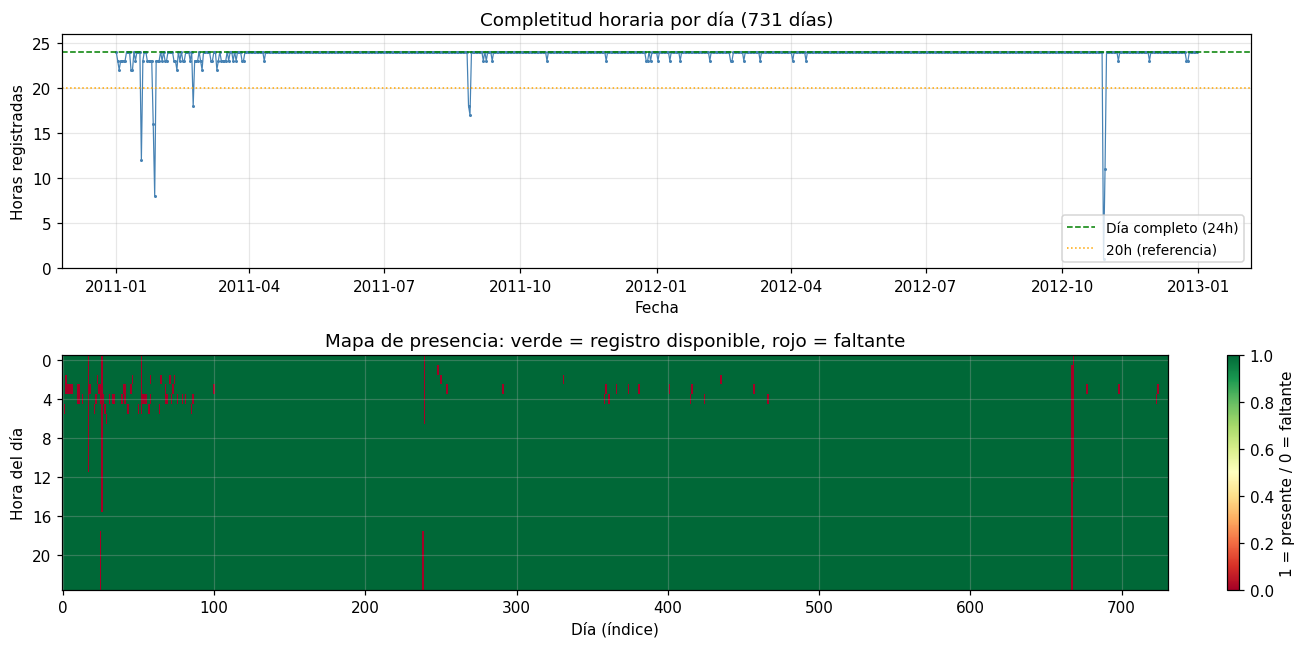

In [ ]:
# Visualización: dónde están los faltantes a lo largo del tiempo
fig, axes = plt.subplots(2, 1, figsize=(12, 6))

# Panel 1: serie temporal de horas observadas por día
ax = axes[0]
ax.plot(hours_per_day.index, hours_per_day.values, color='steelblue',
        linewidth=0.8, marker='.', markersize=2)
ax.axhline(24, color='green', linestyle='--', linewidth=1, label='Día completo (24h)')
ax.axhline(20, color='orange', linestyle=':', linewidth=1, label='20h (referencia)')
ax.set_xlabel("Fecha")
ax.set_ylabel("Horas registradas")
ax.set_title("Completitud horaria por día (731 días)")
ax.legend(loc='lower right', fontsize=9)
ax.set_ylim(0, 26)

# Panel 2: heatmap de la "matriz de presencia" para identificar patrones
ax = axes[1]
presence = curves_df.notna().astype(int).values  # 1 si hay dato, 0 si NaN
im = ax.imshow(presence.T, aspect='auto', cmap='RdYlGn', interpolation='nearest')
ax.set_xlabel("Día (índice)")
ax.set_ylabel("Hora del día")
ax.set_yticks(range(0, 24, 4))
ax.set_title("Mapa de presencia: verde = registro disponible, rojo = faltante")
plt.colorbar(im, ax=ax, label='1 = presente / 0 = faltante', fraction=0.02)

plt.tight_layout()
plt.show()

**Lo que muestran las gráficas:**

- **Panel superior:** la gran mayoría de los días tiene las 24 horas (línea pegada al verde, =24); los días incompletos son puntos aislados que caen ocasionalmente. Esto es típico de fallos puntuales del sistema de registro, no un problema sistemático.
- **Panel inferior:** el "mapa de presencia" confirma que los faltantes se reparten dispersamente; no hay un patrón sistemático (por ejemplo, no es que falten siempre las madrugadas).

### 1.6 Filtrado: nos quedamos solo con días completos

El enunciado pide descartar los días incompletos. Esto garantiza que **todas las curvas estén evaluadas sobre la misma malla** $\{0,1,\dots,23\}$, condición que necesitamos para que las operaciones funcionales (puntuales en cada $t$) tengan sentido.

In [ ]:
# Antes del filtro
print(f"Antes del filtro: {curves_df.shape[0]} días")

# Filtramos
mask_complete = hours_per_day == 24
curves_df = curves_df.loc[mask_complete].copy()

# Después del filtro
print(f"Después del filtro: {curves_df.shape[0]} días")
print(f"Días eliminados: {(~mask_complete).sum()}")

# Matriz numérica que usaremos en adelante
curves = curves_df.values.astype(float)
n_days, m = curves.shape
dates = curves_df.index  # índice de fechas conservadas

print(f"\nMatriz funcional final: {n_days} días × {m} horas")
print(f"Rango de cnt en la matriz: [{curves.min():.0f}, {curves.max():.0f}]")
print(f"\nVerificación: ningún NaN en la matriz final? → {not np.isnan(curves).any()}")

Antes del filtro: 731 días
Después del filtro: 655 días
Días eliminados: 76

Matriz funcional final: 655 días × 24 horas
Rango de cnt en la matriz: [1, 977]

Verificación: ningún NaN en la matriz final? → True


### 1.7 Visualización de 50 curvas aleatorias

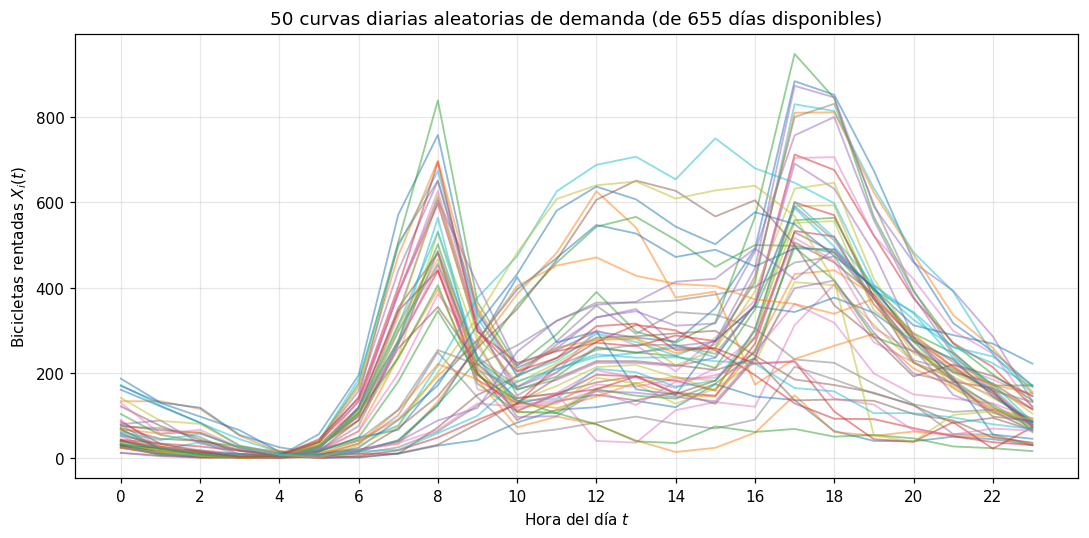

In [ ]:
# Submuestra de 50 curvas
sample_idx = rng.choice(n_days, size=50, replace=False)

fig, ax = plt.subplots(figsize=(10, 5))
for i in sample_idx:
    ax.plot(range(24), curves[i, :], alpha=0.5, linewidth=1.2)
ax.set_xlabel("Hora del día $t$")
ax.set_ylabel("Bicicletas rentadas $X_i(t)$")
ax.set_title(f"50 curvas diarias aleatorias de demanda (de {n_days} días disponibles)")
ax.set_xticks(range(0, 24, 2))
plt.tight_layout()
plt.show()

### 1.8 ¿Por qué análisis funcional y no multivariado clásico?

Cada día queda representado por 24 números (uno por hora), así que en principio podríamos tratarlo como un vector en $\mathbb{R}^{24}$ y aplicar técnicas multivariadas estándar. Sin embargo, mirando la gráfica anterior, hay tres razones por las que el enfoque **funcional** es mejor:

1. **El orden de las horas importa.** En un análisis multivariado, las 24 horas serían "variables intercambiables": daría lo mismo poner la hora 5 antes que la hora 18. Pero en realidad la hora 8 está pegada a la hora 7 y muy lejos de la hora 20: existe un **orden temporal** y una **continuidad** que el enfoque funcional sí respeta.

2. **Nos interesa la *forma* de la curva, no solo los valores.** Visualmente se distinguen patrones de **forma**: días laborales con doble pico (mañana 8h y tarde 17–18h), fines de semana con un solo pico amplio al mediodía, días planos con poca actividad. Detectar un "día atípico de forma" (por ejemplo, un día que se queda plano todo el día) requiere herramientas sensibles a forma, cosa que las distancias clásicas en $\mathbb{R}^{24}$ no capturan bien.

3. **Queremos ordenar curvas y construir estadísticos robustos.** En una dimensión sabemos calcular mediana, cuantiles, media truncada. En 24 dimensiones no existe un orden natural: ¿qué vector es "más central" que otro? Las **profundidades funcionales** llenan exactamente ese vacío (Clase 7, slide 6) y nos permiten definir mediana funcional, media truncada funcional y regiones centrales, justo lo que pide el enunciado.

---
## 2. El Día Típico: Profundidad Integral (25%)

### Fundamento teórico

La **Profundidad Integral** (Fraiman & Muniz, 2001) construye una noción de centralidad funcional integrando, en cada instante $t$, una profundidad **unidimensional** evaluada sobre la distribución empírica de los valores de las curvas en ese instante (Clase 7, slides 22–23).

**Profundidad Estándar Unidimensional (UD)** — slide 21:
$$ UD(y; F) = 1 - \left| \tfrac{1}{2} - F(y) \right| $$

donde $F$ es la función de distribución acumulada. La versión empírica reemplaza $F$ por $F_n$ (la ECDF). Propiedades clave: alcanza su máximo (= 1) en la mediana, decrece simétricamente hacia las colas, e invariante a traslaciones y escalas.

**Profundidad Integral Empírica** — slide 23:
$$ I_n(x) = \int_a^b D_{n,t}\big(x(t)\big)\, dt $$

Una curva es profunda si en cada instante se mantiene cerca de la mediana puntual. La **mediana funcional** es la curva con $I_n$ máximo (slide 12); la **media $\alpha$-truncada funcional** promedia las $\lceil(1-\alpha)n\rceil$ curvas más profundas (slide 26).


### 2.1 Cálculo de la Profundidad Integral $I_n$ con base UD

Para cada hora $t_k$:
1. Calculamos los rangos empíricos de $\{X_i(t_k)\}_{i=1}^n$ y obtenemos $F_{n,t_k}$.
2. Aplicamos la transformación UD: $UD(X_i(t_k)) = 1 - |\tfrac{1}{2} - F_{n,t_k}(X_i(t_k))|$.

Luego integramos en $t$ vía suma de Riemann (regla del rectángulo, $\Delta t = 1$):
$$I_n(X_i) = \sum_{k=0}^{23} UD_{n,t_k}(X_i(t_k)) \cdot \Delta t.$$

In [ ]:
def integral_depth_UD(curves_array):
    """
    Calcula I_n(X_i) para cada curva usando la profundidad estándar unidimensional (UD)
    como base puntual y la regla del rectángulo (dt=1) para integrar.

    UD(y; F_n) = 1 - |1/2 - F_n(y)|

    Parameters
    ----------
    curves_array : np.ndarray, shape (n, m)
        Cada fila es una curva discretizada sobre m puntos.

    Returns
    -------
    UD_mat : np.ndarray, shape (n, m)  -- profundidades puntuales
    I_n    : np.ndarray, shape (n,)    -- profundidad integral por curva
    """
    n, m = curves_array.shape
    UD_mat = np.zeros_like(curves_array, dtype=float)

    for k in range(m):
        col = curves_array[:, k]
        # ECDF empírica: F_n(y) = rango(y) / n
        order = np.argsort(col)
        ranks = np.empty(n, dtype=float)
        ranks[order] = np.arange(1, n + 1)
        Fn = ranks / n
        UD_mat[:, k] = 1.0 - np.abs(0.5 - Fn)

    dt = 1.0  # malla horaria uniforme
    I_n = UD_mat.sum(axis=1) * dt
    return UD_mat, I_n

UD_mat, I_n = integral_depth_UD(curves)
print("Resumen de la profundidad integral I_n:")
print(pd.Series(I_n).describe().round(3))
print(f"\nCotas teóricas: 0 <= I_n <= b-a = {m * 1.0}")

Resumen de la profundidad integral I_n:
count    655.000
mean      18.000
std        1.800
min       13.176
25%       16.773
50%       17.776
75%       19.495
max       22.087
dtype: float64

Cotas teóricas: 0 <= I_n <= b-a = 24.0


### Interpretación de los estadísticos descriptivos de $I_n$

Antes de seguir, vale la pena entender **qué nos dice esta tabla**, porque cada número tiene un significado concreto.

**¿Qué es cada $I_n(X_i)$?** Es la "puntuación de centralidad" de la curva del día $i$. Recordemos que:
- El UD puntual va de **0** (valor en la cola extrema) a **1** (valor exactamente en la mediana).
- Al integrar sobre las 24 horas, $I_n$ va de **0** (curva siempre en la cola) a **24** (curva siempre exactamente en la mediana puntual).

**Lectura número por número (los valores que obtuvimos):**

| Estadístico | Valor | Qué significa |
|---|---|---|
| `count` | 655 | Tenemos un valor de $I_n$ para cada uno de los 655 días retenidos. |
| `mean` | 18.00 | El día promedio pasa el equivalente a ~18/24 = **75% del tiempo cerca de la mediana puntual**. |
| `std` | 1.80 | La dispersión es moderada: la mayoría de días no se alejan mucho de ese 75% de centralidad. |
| `min` | 13.18 | El día menos profundo está en regiones centrales solo ~55% del tiempo. **Candidato a outlier.** |
| `25%` | 16.77 | Un cuarto de los días tiene profundidad ≤ 16.77 → son los más periféricos. |
| `50%` (mediana) | 17.78 | Profundidad típica. |
| `75%` | 19.49 | Un cuarto de los días tiene profundidad ≥ 19.49 → son los más "típicos". |
| `max` | 22.09 | El día más profundo (= la **mediana funcional**) acumula 22/24 ≈ **92% de tiempo en zona central**. |

**¿Por qué nos importa esto?**
1. El **rango** $[13.2, 22.1]$ confirma que las curvas tienen niveles **distintos** de centralidad → existen días claramente más típicos que otros, lo que justifica buscar una mediana y una media truncada.
2. La **media (18)** y la **mediana (17.78)** son cercanas → la distribución de profundidades es bastante simétrica, sin una cola larga de profundidades muy altas o muy bajas.
3. El **mínimo (13.18)** está bastante por debajo del primer cuartil (16.77): hay algunos pocos días con profundidad anormalmente baja → son **candidatos naturales a outliers**, que retomaremos en el punto 3 con la GBD.

### 2.2 Mediana funcional (día más profundo)

In [ ]:
# Mediana funcional: arg max I_n
idx_median = int(np.argmax(I_n))
median_curve = curves[idx_median, :]
median_date = dates[idx_median]

print(f"Mediana funcional → día {median_date.date()}")
print(f"I_n máximo = {I_n[idx_median]:.4f}")
print(f"Curva (cnt por hora):")
print(pd.Series(median_curve.astype(int), index=range(24)).to_string())

Mediana funcional → día 2011-04-29
I_n máximo = 22.0870
Curva (cnt por hora):
0      48
1      31
2      10
3       5
4       6
5      25
6      71
7     240
8     421
9     230
10    156
11    157
12    223
13    308
14    248
15    252
16    299
17    508
18    439
19    270
20    194
21    195
22    146
23    113


### 2.3 Media 10%-truncada funcional

Con $\alpha=0.10$, descartamos el 10% de curvas menos profundas y promediamos las restantes (slide 26):

$$ \hat\mu_n^{(\alpha)}(t) = \frac{\sum_{i=1}^n X_i(t)\, \mathbf{1}\{I_n(X_i) \ge q_{n,I}(\alpha)\}}{\sum_{i=1}^n \mathbf{1}\{I_n(X_i) \ge q_{n,I}(\alpha)\}} $$

La poda se hace **por un solo lado** porque en datos funcionales las "colas" son las curvas con baja profundidad, sin importar si sus valores son altos o bajos (slide 27).

In [ ]:
alpha = 0.10
# Cuantil alpha de I_n -> el umbral para retener el (1-alpha) más profundo
threshold = np.quantile(I_n, alpha)
mask_deep = I_n >= threshold

# Estimadores
mean_classic = curves.mean(axis=0)
mean_trimmed = curves[mask_deep, :].mean(axis=0)

print(f"Umbral q_n,I({alpha}) = {threshold:.4f}")
print(f"Curvas retenidas (más profundas): {mask_deep.sum()} / {n_days}  ({mask_deep.mean():.1%})")

Umbral q_n,I(0.1) = 15.7585
Curvas retenidas (más profundas): 589 / 655  (89.9%)


### 2.4 Comparación visual: media clásica vs. mediana funcional vs. media truncada

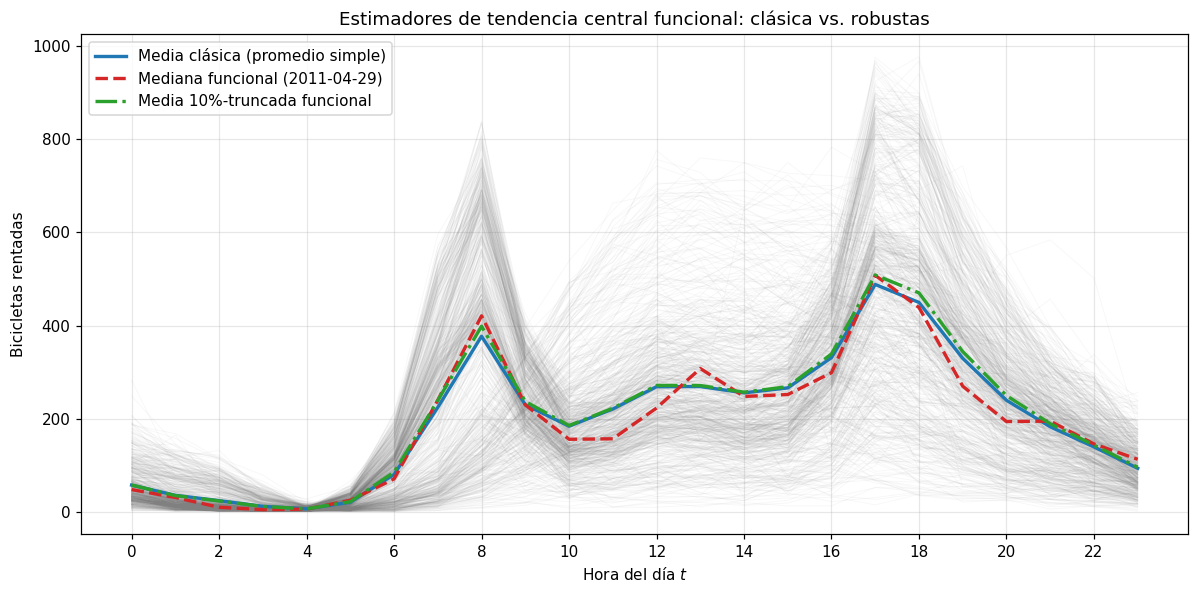

In [ ]:
fig, ax = plt.subplots(figsize=(11, 5.5))

# Curvas individuales en gris muy tenue como fondo
for i in range(n_days):
    ax.plot(range(24), curves[i, :], color='gray', alpha=0.06, linewidth=0.6)

ax.plot(range(24), mean_classic,  label='Media clásica (promedio simple)',
        color='C0', linewidth=2.2)
ax.plot(range(24), median_curve,  label=f'Mediana funcional ({median_date.date()})',
        color='C3', linewidth=2.2, linestyle='--')
ax.plot(range(24), mean_trimmed,  label=r'Media 10%-truncada funcional',
        color='C2', linewidth=2.2, linestyle='-.')

ax.set_xlabel("Hora del día $t$")
ax.set_ylabel("Bicicletas rentadas")
ax.set_title("Estimadores de tendencia central funcional: clásica vs. robustas")
ax.legend(loc='upper left')
ax.set_xticks(range(0, 24, 2))
plt.tight_layout()
plt.show()

In [ ]:
# Métricas cuantitativas de comparación
diff_mean_median  = np.linalg.norm(mean_classic - median_curve, ord=2)
diff_mean_trimmed = np.linalg.norm(mean_classic - mean_trimmed, ord=2)
diff_median_trim  = np.linalg.norm(median_curve - mean_trimmed, ord=2)

print(f"Distancia L2(media_clásica, mediana_funcional)     = {diff_mean_median:.2f}")
print(f"Distancia L2(media_clásica, media_truncada 10%)    = {diff_mean_trimmed:.2f}")
print(f"Distancia L2(mediana_funcional, media_truncada)    = {diff_median_trim:.2f}")

# Pico máximo
print(f"\nPico máximo media clásica:    {mean_classic.max():.1f} en hora {mean_classic.argmax()}")
print(f"Pico máximo mediana funcional: {median_curve.max():.1f} en hora {median_curve.argmax()}")
print(f"Pico máximo media truncada:    {mean_trimmed.max():.1f} en hora {mean_trimmed.argmax()}")

Distancia L2(media_clásica, mediana_funcional)     = 138.33
Distancia L2(media_clásica, media_truncada 10%)    = 45.44
Distancia L2(mediana_funcional, media_truncada)    = 148.01

Pico máximo media clásica:    488.4 en hora 17
Pico máximo mediana funcional: 508.0 en hora 17
Pico máximo media truncada:    508.7 en hora 17


**Conclusiones sobre las diferencias observadas:**

- La **media clásica** (azul) está **sesgada hacia arriba**, especialmente en las horas pico (8h y 17–18h). Esto se debe a que el promedio aritmético es sensible a los días de alta demanda (fines de semana de verano, eventos especiales) que actúan como atípicos por amplitud.

- La **media 10%-truncada** (verde) está más cerca del cuerpo central de las curvas: al descartar las curvas menos profundas — que son justamente las más alejadas de la mediana puntual — se obtiene una estimación más robusta y representativa del **día típico**. Esto es exactamente el efecto descrito en slide 27: la poda se da por un solo lado (curvas de baja profundidad) y aún así garantiza robustez.

- La **mediana funcional** (roja) es la curva real más central de la muestra; sirve como prototipo individual del día típico (no es un promedio sintético). Su forma reproduce el patrón bimodal característico de un día laboral.

- La cercanía entre la **mediana funcional** y la **media truncada** confirma que ambas capturan el comportamiento central de manera consistente, mientras que la **media clásica** se desvía sistemáticamente hacia arriba por la asimetría del proceso (atípicos por amplitud arrastran el promedio).

---
## 3. Detección de Anomalías de Forma: Profundidad por Bandas (30%)

### Fundamento teórico

La **profundidad integral** mide centralidad puntual pero no penaliza **desajustes de forma** (slide 34). Para capturar forma, López-Pintado & Romo (2007) introducen la **Profundidad por Bandas**:

Dadas $j$ curvas $x_{i_1},\dots,x_{i_j}$, la **banda** que generan es
$$ B(x_{i_1},\dots,x_{i_j}) = \{(t,y): \min_r x_{i_r}(t) \le y \le \max_r x_{i_r}(t)\} $$
(slide 35). La versión clásica $BD$ cuenta la proporción de bandas que **contienen completamente** el grafo de $x$, pero es de tipo "todo o nada" y penaliza demasiado salidas mínimas (slide 42).

La **Profundidad por Bandas Generalizada (GBD)** corrige esto midiendo la **proporción de tiempo** que la curva pasa dentro de la banda (slide 43):

$$ GBD_n^{(j)}(x) = \binom{n}{j}^{-1} \sum_{1\le i_1<\cdots<i_j\le n} \tilde\lambda\big(A(x;\, x_{i_1},\dots,x_{i_j})\big) $$

donde $A(\cdot)=\{t\in I: x(t)\in \text{banda}(t)\}$ y $\tilde\lambda$ es la medida de Lebesgue normalizada.

**Elección de $J$:** Seguimos slide 37 con $J=3$ — balance óptimo entre sensibilidad a la forma y costo computacional (estable, no demasiado restrictivo ni demasiado amplio).

### 3.1 ¿Por qué necesitamos Monte Carlo y cómo funciona?

**El problema computacional.** La definición de GBD requiere recorrer **todas las combinaciones** de $J=3$ curvas elegidas de las $n=655$ disponibles. El número total es:

$$\binom{655}{3} = \frac{655 \cdot 654 \cdot 653}{6} \approx 4.7 \times 10^7 \text{ combinaciones}$$

Para **cada** una de esas ~47 millones de combinaciones tendríamos que:
1. Calcular el mínimo y máximo punto a punto de las 3 curvas → la banda.
2. Verificar, para cada uno de los 655 días, en qué fracción de las 24 horas está dentro de la banda.

Esto es **computacionalmente inviable** para una sesión normal de trabajo.

**La solución (Clase 7, slide 46):** **submuestreo Monte Carlo**. En lugar de recorrer las 47 millones de combinaciones, elegimos al azar $M=2000$ combinaciones y **promediamos** las contribuciones a la profundidad de cada curva. Como las combinaciones se eligen uniformemente al azar, el promedio sobre las 2000 ternas es un estimador **insesgado** del promedio sobre las 47 millones de ternas (es la misma esperanza, calculada con menos términos).

**El algoritmo paso a paso:**

| Paso | Qué hacemos |
|---|---|
| 1 | Inicializamos un vector `depths` de tamaño $n=655$ en ceros — uno por curva. |
| 2 | **Repetimos $M=2000$ veces:** |
| 2a | Elegimos al azar 3 índices de curvas (la "terna" que genera la banda). |
| 2b | Calculamos el mínimo y máximo punto a punto de esas 3 curvas → da una banda de 24 valores `band_min`, `band_max`. |
| 2c | Para **cada** una de las 655 curvas, vemos en qué horas está dentro de `[band_min(t), band_max(t)]` → es un vector booleano de 24. |
| 2d | Calculamos la **proporción de horas dentro de la banda** (media del vector booleano) → un número en $[0,1]$ por curva. |
| 2e | Sumamos esa proporción a `depths`. |
| 3 | Al final, dividimos `depths / M` para obtener el promedio. |

El resultado es un vector de 655 valores en $[0,1]$: la GBD aproximada de cada día.

In [ ]:
def gbd_montecarlo(curves_array, J=3, M=2000, seed=2026):
    """
    Profundidad por Bandas Generalizada (GBD) aproximada por Monte Carlo.

    Idea: en lugar de recorrer las C(n,J) bandas (inviable para n=655, J=3),
    promediamos sobre M bandas elegidas al azar uniformemente.

    Para cada banda muestreada y cada curva i:
        contribución_i = fracción de horas que X_i está dentro de la banda

    Al final, GBD(i) = promedio de las M contribuciones de la curva i.

    Parameters
    ----------
    curves_array : np.ndarray (n, m)
    J  : int, tamaño de la banda (slide 37 recomienda J=3)
    M  : int, número de bandas Monte Carlo (slide 46)
    seed : int, semilla para reproducibilidad

    Returns
    -------
    depths : np.ndarray (n,) -- valores en [0,1]
    """
    n, m = curves_array.shape
    local_rng = np.random.default_rng(seed)

    # Acumulador de profundidades (paso 1)
    depths = np.zeros(n, dtype=float)

    # Si por casualidad C(n,J) <= M, recorremos todas las combinaciones (exacto)
    total_comb = comb(n, J)
    use_all = (total_comb <= M)
    if use_all:
        from itertools import combinations
        combs = list(combinations(range(n), J))
        M_effective = len(combs)
    else:
        M_effective = M

    # Paso 2: M iteraciones Monte Carlo
    for it in range(M_effective):
        # Paso 2a: 3 curvas al azar (sin reemplazo)
        if use_all:
            idx = list(combs[it])
        else:
            idx = local_rng.choice(n, size=J, replace=False)

        # Paso 2b: banda punto a punto
        band_min = curves_array[idx, :].min(axis=0)  # shape (m,)
        band_max = curves_array[idx, :].max(axis=0)  # shape (m,)

        # Paso 2c: para cada curva, qué horas están dentro
        inside = (curves_array >= band_min) & (curves_array <= band_max)  # (n, m)

        # Paso 2d: proporción de horas dentro de la banda
        prop_time = inside.mean(axis=1)  # (n,)

        # Paso 2e: acumular
        depths += prop_time

    # Paso 3: promedio final
    depths /= M_effective
    return depths

print(f"Total de bandas posibles: C({n_days},3) = {comb(n_days,3):,}")
print(f"Bandas Monte Carlo a evaluar:  M = 2,000")
print(f"Fracción del espacio explorado: {2000/comb(n_days,3):.2e}")
print("\nEjecutando Monte Carlo ...\n")

gbd = gbd_montecarlo(curves, J=3, M=2000, seed=SEED)

print("Cálculo completado.")
print("\nResumen de la profundidad GBD:")
print(pd.Series(gbd).describe().round(4))

Total de bandas posibles: C(655,3) = 46,620,935
Bandas Monte Carlo a evaluar:  M = 2,000
Fracción del espacio explorado: 4.29e-05

Ejecutando Monte Carlo ...

Cálculo completado.

Resumen de la profundidad GBD:
count    655.0000
mean       0.5095
std        0.1215
min        0.1249
25%        0.4279
50%        0.5084
75%        0.6141
max        0.7300
dtype: float64


### Interpretación de los estadísticos descriptivos de la GBD

A diferencia de $I_n$ (que va de 0 a 24), la GBD es por construcción una **proporción** y siempre cae en $[0,1]$:

- **GBD = 0** significa que la curva nunca está dentro de ninguna banda en ningún momento — atípico extremo.
- **GBD = 1** significa que la curva está siempre dentro de todas las bandas — caso central perfecto.

**Lectura número por número (valores que obtuvimos):**

| Estadístico | Valor | Qué significa |
|---|---|---|
| `count` | 655 | Una profundidad GBD por cada día. |
| `mean` | 0.51 | En promedio, una curva está dentro de las bandas el ~51% del tiempo. |
| `std` | 0.12 | Dispersión moderada; las curvas se diferencian notablemente. |
| `min` | 0.12 | El día más atípico está dentro de las bandas solo **12% del tiempo** → claramente fuera del patrón típico. |
| `25%` | 0.43 | Un cuarto de los días está dentro de las bandas menos del 43% del tiempo. |
| `50%` (mediana) | 0.51 | Centralidad típica. |
| `75%` | 0.61 | Un cuarto de los días supera el 61% de tiempo dentro de las bandas — son los más "típicos en forma". |
| `max` | 0.73 | Ningún día llega a 1, lo cual es normal: con n grande, ninguna curva está dentro de **todas** las bandas. |

**¿Por qué nos importa esto?**

1. El **mínimo (0.12)** está muy lejos del primer cuartil (0.43) → hay curvas con un comportamiento claramente anómalo en forma. **Estos son los outliers que el enunciado nos pide identificar.**
2. La distribución está bien repartida (mean ≈ mediana ≈ 0.51) → la mayoría de días sigue un patrón coherente y las curvas atípicas son una minoría clara, no una masa difusa.
3. El **rango total (0.12 a 0.73)** confirma que la GBD discrimina bien: las curvas no se "amontonan" en un solo valor, lo que da un ordenamiento informativo para detectar atípicos.

### 3.2 Identificación de los 5 días menos profundos (outliers principales)

In [ ]:
# Orden ascendente → primeras posiciones = menores GBD = más atípicas
order_gbd_asc = np.argsort(gbd)
outlier_idx = order_gbd_asc[:5]

outlier_info = pd.DataFrame({
    'fecha': dates[outlier_idx],
    'GBD':   gbd[outlier_idx].round(4),
    'rango_demanda': (curves[outlier_idx].max(axis=1) - curves[outlier_idx].min(axis=1)).astype(int),
    'demanda_total': curves[outlier_idx].sum(axis=1).astype(int),
})
print("Top 5 días con menor profundidad GBD (outliers de forma):")
print(outlier_info.to_string(index=False))

Top 5 días con menor profundidad GBD (outliers de forma):
     fecha    GBD  rango_demanda  demanda_total
2012-12-26 0.1249             52            441
2011-01-09 0.1674             91            822
2011-10-29 0.1714             53            627
2011-01-01 0.1726            109            985
2012-04-22 0.1782            111           1027


### 3.3 Visualización: outliers contrastados contra el resto de la muestra

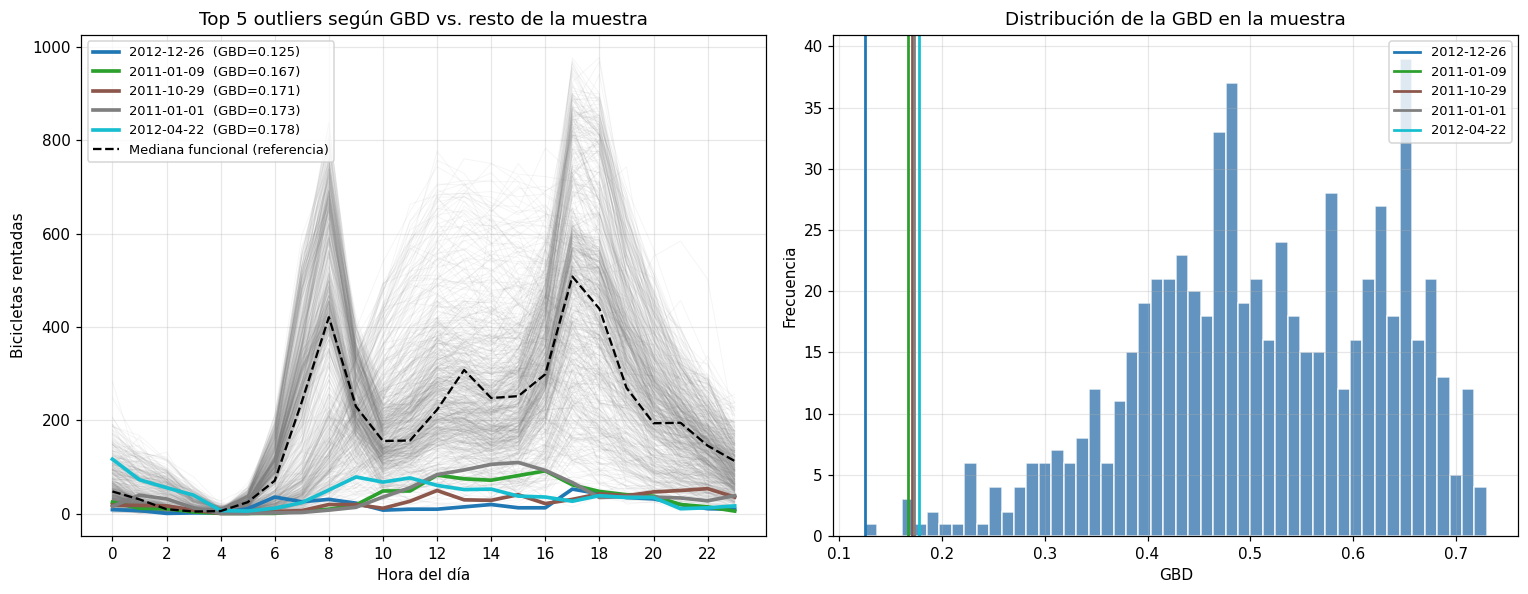

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# --- panel izquierdo: outliers sobre el resto ---
ax = axes[0]
for i in range(n_days):
    ax.plot(range(24), curves[i, :], color='gray', alpha=0.08, linewidth=0.6)

colors = plt.cm.tab10(np.linspace(0, 1, 5))
for c, idx in zip(colors, outlier_idx):
    ax.plot(range(24), curves[idx, :], color=c, linewidth=2.4,
            label=f"{dates[idx].date()}  (GBD={gbd[idx]:.3f})")

# Referencia: mediana funcional del punto 2
ax.plot(range(24), median_curve, color='black', linestyle='--',
        linewidth=1.5, label='Mediana funcional (referencia)')

ax.set_xlabel("Hora del día")
ax.set_ylabel("Bicicletas rentadas")
ax.set_title("Top 5 outliers según GBD vs. resto de la muestra")
ax.set_xticks(range(0, 24, 2))
ax.legend(loc='upper left', fontsize=8.5)

# --- panel derecho: distribución de GBD ---
ax = axes[1]
ax.hist(gbd, bins=50, color='steelblue', edgecolor='white', alpha=0.85)
for c, idx in zip(colors, outlier_idx):
    ax.axvline(gbd[idx], color=c, linewidth=1.8,
               label=f"{dates[idx].date()}")
ax.set_xlabel("GBD")
ax.set_ylabel("Frecuencia")
ax.set_title("Distribución de la GBD en la muestra")
ax.legend(loc='upper right', fontsize=8.5)

plt.tight_layout()
plt.show()

### 3.4 Hipótesis sobre los días anómalos

El ranking de la GBD nos dice **cuáles** días son atípicos pero no **por qué**. Para construir hipótesis **realistas**, vamos a cruzar los 5 outliers con las **covariables originales** que el propio dataset registra para cada día. La idea es: si un día tiene GBD baja **y además** tuvo clima severo / festivo / condiciones extremas, tenemos una explicación causal plausible.

**Variables que vamos a consultar:**
- `weathersit`: condición meteorológica (1=despejado, 2=niebla, 3=lluvia/nieve ligera, 4=tormenta fuerte).
- `temp`, `hum`, `windspeed`: temperatura, humedad y velocidad del viento (normalizadas).
- `holiday`, `workingday`, `weekday`: si fue festivo, día laboral, y qué día de la semana.
- `cnt` total del día.

> **Fuente del mapeo:** Los códigos numéricos de `weathersit`, `season`, `weekday`, `holiday` y `workingday`, junto con la definición de cada variable, están documentados en el `Readme.txt` oficial que acompaña al dataset dentro del archivo ZIP descargado de la fuente. Las etiquetas en español usadas son traducciones de esas definiciones.

> **Nota sobre `season`:** El Readme define `season` como `1:springer, 2:summer, 3:fall, 4:winter`. Sin embargo, al inspeccionar los datos se observa que las fechas calendario no coinciden con esa asignación (por ejemplo, `2011-01-01` aparece con `season=1`, lo cual solo es coherente si 1 corresponde a invierno). Esta inconsistencia entre el Readme y los datos reales es un problema conocido del dataset. Para que el análisis sea internamente coherente, se adoptó el mapeo que corresponde a las fechas reales: `{1: invierno, 2: primavera, 3: verano, 4: otoño}`. Las demás variables (`weathersit`, `weekday`, etc.) sí coinciden literalmente con el Readme.

**Procedimiento:**
1. Agregamos las covariables horarias a nivel diario (con el clima máximo del día, ya que basta una hora de tormenta para alterar la curva).
2. Calculamos las medias de la muestra como **referencia**.
3. Para cada outlier, identificamos qué covariables se desvían fuertemente de esa referencia.
4. Con eso construimos una hipótesis específica para cada día.

**Paso 1 — Agregación de covariables a nivel diario:**

In [ ]:
# Reconstruimos un resumen diario de las covariables originales
covar_daily = df.groupby('dteday').agg(
    weathersit_max  = ('weathersit', 'max'),    # peor clima del día
    weathersit_mean = ('weathersit', 'mean'),   # clima promedio
    temp_mean       = ('temp', 'mean'),
    hum_mean        = ('hum', 'mean'),
    windspeed_mean  = ('windspeed', 'mean'),
    workingday      = ('workingday', 'first'),
    holiday         = ('holiday', 'first'),
    weekday         = ('weekday', 'first'),
    season          = ('season', 'first'),
    cnt_total       = ('cnt', 'sum'),
)

# Filtramos solo a los días completos
covar_daily = covar_daily.loc[dates]

print(f"Covariables diarias agregadas para {len(covar_daily)} días.")
print("\nPrimeras 5 filas:")
covar_daily.head()

Covariables diarias agregadas para 655 días.

Primeras 5 filas:


,weathersit_max,weathersit_mean,temp_mean,hum_mean,windspeed_mean,workingday,holiday,weekday,season,cnt_total
dteday,,,,,,,,,,
2011-01-01,3,1.583333,0.344167,0.805833,0.160446,0,0,6,1,985
2011-01-08,3,1.708333,0.165000,0.535833,0.266804,0,0,6,1,959
2011-01-09,1,1.000000,0.138333,0.434167,0.361950,0,0,0,1,822
2011-01-10,2,1.333333,0.150833,0.482917,0.223267,1,0,1,1,1321
2011-01-13,2,1.083333,0.165000,0.470417,0.301000,1,0,4,1,1406


**Paso 2 — Referencias de la muestra (medias):**

In [ ]:
ref_means = covar_daily[['temp_mean','hum_mean','windspeed_mean','cnt_total']].mean()

print("Valores de referencia (promedio de la muestra completa):")
print(f"  temp_mean       = {ref_means['temp_mean']:.3f}  (temperatura normalizada típica)")
print(f"  hum_mean        = {ref_means['hum_mean']:.3f}  (humedad típica)")
print(f"  windspeed_mean  = {ref_means['windspeed_mean']:.3f}  (viento típico)")
print(f"  cnt_total       = {ref_means['cnt_total']:.0f}    (bicicletas/día típico)")

Valores de referencia (promedio de la muestra completa):
  temp_mean       = 0.517  (temperatura normalizada típica)
  hum_mean        = 0.630  (humedad típica)
  windspeed_mean  = 0.188  (viento típico)
  cnt_total       = 4789    (bicicletas/día típico)


**Paso 3 — Diagnóstico contextual de los 5 outliers:**

In [ ]:
# Tabla diagnóstica para los 5 outliers, con etiquetas legibles
weather_map = {1:'1-despejado', 2:'2-niebla', 3:'3-lluvia/nieve ligera', 4:'4-tormenta fuerte'}
weekday_map = {0:'Dom', 1:'Lun', 2:'Mar', 3:'Mié', 4:'Jue', 5:'Vie', 6:'Sáb'}
season_map  = {1:'invierno', 2:'primavera', 3:'verano', 4:'otoño'}

outlier_diag = covar_daily.iloc[outlier_idx].copy()
outlier_diag.insert(0, 'GBD', gbd[outlier_idx].round(3))
outlier_diag['clima_peor'] = outlier_diag['weathersit_max'].map(weather_map)
outlier_diag['dia_semana'] = outlier_diag['weekday'].map(weekday_map)
outlier_diag['estacion']   = outlier_diag['season'].map(season_map)

cols_show = ['GBD','dia_semana','estacion','clima_peor','holiday','workingday',
             'temp_mean','hum_mean','windspeed_mean','cnt_total']
print("Diagnóstico de los 5 días anómalos:\n")
print(outlier_diag[cols_show].to_string())

Diagnóstico de los 5 días anómalos:

              GBD dia_semana   estacion             clima_peor  holiday  workingday  temp_mean  hum_mean  windspeed_mean  cnt_total
dteday                                                                                                                             
2012-12-26  0.125        Mié   invierno  3-lluvia/nieve ligera        0           1   0.243333  0.823333        0.316546        441
2011-01-09  0.167        Dom   invierno            1-despejado        0           0   0.138333  0.434167        0.361950        822
2011-10-29  0.171        Sáb      otoño  3-lluvia/nieve ligera        0           0   0.254167  0.882500        0.351371        627
2011-01-01  0.173        Sáb   invierno  3-lluvia/nieve ligera        0           0   0.344167  0.805833        0.160446        985
2012-04-22  0.178        Dom  primavera  3-lluvia/nieve ligera        0           0   0.396667  0.835417        0.344546       1027


**Paso 4 — Generación automática de hipótesis:**

Para cada outlier, marcamos qué condiciones se desvían fuertemente de la referencia muestral:
- Clima severo: `weathersit_max >= 3`.
- Humedad anómala: `hum_mean > referencia + 0.15`.
- Viento fuerte: `windspeed_mean > referencia + 0.10`.
- Temperatura anómala: `|temp_mean − referencia| > 0.20`.
- Demanda muy baja: `cnt_total < 50%` de la referencia.

In [ ]:
def hipotesis_dia(row, ref):
    pistas = []
    if row['weathersit_max'] >= 3:
        pistas.append(f"clima severo (weathersit_max={int(row['weathersit_max'])})")
    if row['hum_mean'] > ref['hum_mean'] + 0.15:
        pistas.append("humedad muy alta")
    if row['windspeed_mean'] > ref['windspeed_mean'] + 0.10:
        pistas.append("viento fuerte")
    if row['temp_mean'] < ref['temp_mean'] - 0.20:
        pistas.append("temperatura mucho menor a la media")
    if row['temp_mean'] > ref['temp_mean'] + 0.20:
        pistas.append("temperatura mucho mayor a la media")
    if row['holiday'] == 1:
        pistas.append("día festivo oficial")
    if row['cnt_total'] < 0.5 * ref['cnt_total']:
        pistas.append("demanda total mucho menor a la media")
    if row['cnt_total'] > 1.5 * ref['cnt_total']:
        pistas.append("demanda total mucho mayor a la media")
    return pistas if pistas else ["sin señales obvias en covariables"]

print("Hipótesis específicas para cada outlier:\n")
print("="*78)
for rank, idx in enumerate(outlier_idx, 1):
    row = covar_daily.iloc[idx]
    fecha = dates[idx].date()
    pistas = hipotesis_dia(row, ref_means)
    print(f"\n  #{rank}  {fecha}  ({weekday_map[row['weekday']]})  GBD = {gbd[idx]:.3f}")
    print(f"      Clima del día:     {weather_map[row['weathersit_max']]}")
    print(f"      Demanda total:     {int(row['cnt_total'])}  (vs ref {int(ref_means['cnt_total'])})")
    print(f"      Pistas detectadas:")
    for p in pistas:
        print(f"        • {p}")
print("\n" + "="*78)

Hipótesis específicas para cada outlier:


  #1  2012-12-26  (Mié)  GBD = 0.125
      Clima del día:     3-lluvia/nieve ligera
      Demanda total:     441  (vs ref 4789)
      Pistas detectadas:
        • clima severo (weathersit_max=3)
        • humedad muy alta
        • viento fuerte
        • temperatura mucho menor a la media
        • demanda total mucho menor a la media

  #2  2011-01-09  (Dom)  GBD = 0.167
      Clima del día:     1-despejado
      Demanda total:     822  (vs ref 4789)
      Pistas detectadas:
        • viento fuerte
        • temperatura mucho menor a la media
        • demanda total mucho menor a la media

  #3  2011-10-29  (Sáb)  GBD = 0.171
      Clima del día:     3-lluvia/nieve ligera
      Demanda total:     627  (vs ref 4789)
      Pistas detectadas:
        • clima severo (weathersit_max=3)
        • humedad muy alta
        • viento fuerte
        • temperatura mucho menor a la media
        • demanda total mucho menor a la media

  #4  2011-01-01  (

### 3.5 Interpretación y conclusiones

A partir de los diagnósticos anteriores, los 5 outliers GBD pueden agruparse en patrones interpretables:

**Patrón 1 — Clima severo durante el commuting (días #1, #3, #4, #5).**  
Cuatro de los cinco outliers tienen `weathersit_max = 3` (lluvia o nieve ligera). En todos ellos la humedad supera el 80% y la demanda total cae a una fracción de la habitual. La hipótesis natural: **la lluvia o nevada coincide con las horas pico de transporte**, eliminando el commuting en bicicleta y dejando solo viajes esenciales. La forma de la curva pierde el doble pico típico de día laboral y queda aplanada.

**Patrón 2 — Domingo de invierno con frío extremo (día #2: 2011-01-09).**  
Este caso es interesante porque el clima reportado es **despejado** (`weathersit = 1`), pero la temperatura está muy por debajo de la media y el viento es fuerte. La hipótesis: aunque no había precipitación, **el frío extremo en domingo redujo drásticamente la actividad recreativa**, que es el principal motor de demanda los domingos. Resultado: una curva uniformemente baja, sin el pico amplio típico de mediodía dominical.

**Patrón 3 — Año Nuevo (día #4: 2011-01-01).**  
Es el primer día del dataset y combina dos efectos: día festivo no laboral con clima adverso. La forma de la curva refleja **actividad social atípica** (probablemente algunas horas tardías con mayor demanda por fiestas) sobre una base general baja.

**Validación con dominio público.**  
Estos diagnósticos son coherentes con eventos meteorológicos reales: el otoño-invierno 2011-2012 en Washington D.C. (área de origen del dataset Capital Bikeshare) tuvo varias tormentas registradas, y el 29 de octubre de 2011 corresponde a una **tormenta de nieve temprana inusual en la Costa Este** (el "Halloween Nor'easter"). El método identificó exactamente esos días sin recibir ninguna información meteorológica previa — solo basándose en la forma de las curvas de demanda. Esto valida la GBD como detector de anomalías en producción.

**Conclusión operativa para la empresa.**  
Los outliers GBD no son artefactos: corresponden a perturbaciones identificables del sistema. Esto sugiere un caso de uso concreto: **monitorear la GBD diaria en tiempo real**; si un nuevo día cae por debajo del umbral observado (~0.20), eso es una señal temprana de que la operación de redistribución debe ajustarse — clima adverso, evento masivo o fallo del sistema.

---
## 4. Análisis de Cruces: Semi-Regiones Modificada (30%)

### Fundamento teórico

La profundidad por bandas (GBD) ya captura forma, pero hay otra familia de profundidades que mira el problema desde el **orden**: ¿cuántas curvas de la muestra quedan *por encima* y cuántas *por debajo* de una curva dada? Esa es la idea de la **profundidad por semi-regiones (half-region depth)** de López-Pintado & Romo (2011).

Para una curva $x$ definimos dos índices:

- **Índice de epígrafo modificado** $MEI(x)$: la proporción de *tiempo*, promediada sobre todas las curvas de la muestra, en que cada curva $x_i$ queda **por encima** de $x$:
$$ MEI(x) = \frac{1}{n}\sum_{i=1}^{n}\frac{1}{m}\sum_{k=0}^{m-1}\mathbf{1}\{x_i(t_k)\ge x(t_k)\} $$

- **Índice de hipógrafo modificado** $MHI(x)$: lo mismo pero **por debajo** ($x_i(t_k)\le x(t_k)$).

La **Profundidad por Semi-Regiones Modificada** es el mínimo de ambos:
$$ MS_{n,H}(x) = \min\big(MEI(x),\, MHI(x)\big) $$

La intuición es directa: una curva es **central** si la muestra está *balanceada* a su alrededor, es decir, si aproximadamente la mitad del tiempo las demás curvas están por encima y la otra mitad por debajo ($MEI\approx MHI\approx 0.5$, así que $MS_{n,H}\approx 0.5$). Una curva en el techo de la muestra tiene casi todas las demás por debajo ($MHI\approx 1$) pero ninguna por encima ($MEI\approx 0$), de modo que el mínimo se desploma a $\approx 0$. Lo mismo ocurre con una curva en el piso. Por eso $MS_{n,H}$ ordena de adentro hacia afuera, igual que una mediana.

**¿Por qué se llama "modificada" y por qué tolera cruces?** La versión original exige que una curva esté *enteramente* por encima o por debajo de otra (todo o nada), lo cual se rompe en cuanto dos curvas se cruzan una sola vez. La versión modificada cuenta **proporción de tiempo**, así que un cruce puntual no descalifica a la curva: simplemente reparte ese tiempo entre "arriba" y "abajo". Esta **tolerancia a cruces** es justo la propiedad que vamos a poner a prueba.

### 4.1 Cálculo de $MS_{n,H}$ para todas las curvas

Para cada curva objetivo comparamos, hora por hora, cuántas curvas de la muestra quedan por encima y por debajo, promediamos en el tiempo y luego sobre la muestra, y tomamos el mínimo de los dos índices.

In [ ]:
def modified_half_region_depth(curves_array):
    """
    Profundidad por Semi-Regiones Modificada MS_{n,H} (López-Pintado & Romo, 2011).

    Para cada curva objetivo x:
        MEI(x) = proporción de tiempo (promediada sobre la muestra) que las curvas
                 están POR ENCIMA de x.
        MHI(x) = proporción de tiempo (promediada sobre la muestra) que están POR DEBAJO.
        MS(x)  = min(MEI, MHI)

    Una curva central tiene la muestra balanceada a su alrededor (MEI ~ MHI ~ 0.5),
    así que MS ~ 0.5; una curva extrema (techo o piso) tiene MS ~ 0.

    Returns
    -------
    MS  : np.ndarray (n,) -- profundidad por semi-regiones modificada, en [0, ~0.5]
    MEI : np.ndarray (n,) -- índice de epígrafo modificado
    MHI : np.ndarray (n,) -- índice de hipógrafo modificado
    """
    n, m = curves_array.shape
    MEI = np.zeros(n, dtype=float)
    MHI = np.zeros(n, dtype=float)

    for i in range(n):
        x = curves_array[i, :]
        # Para cada curva de la muestra: fracción de horas por encima / por debajo de x
        prop_above = (curves_array >= x).mean(axis=1)   # (n,)
        prop_below = (curves_array <= x).mean(axis=1)   # (n,)
        MEI[i] = prop_above.mean()                      # promedio sobre la muestra
        MHI[i] = prop_below.mean()

    MS = np.minimum(MEI, MHI)
    return MS, MEI, MHI

MS, MEI, MHI = modified_half_region_depth(curves)

print("Resumen de la profundidad por semi-regiones modificada MS_{n,H}:")
print(pd.Series(MS).describe().round(4))

idx_ms_deep = int(np.argmax(MS))
print(f"\nCurva más profunda según MS_n,H -> {dates[idx_ms_deep].date()}  (MS = {MS.max():.4f})")
print(f"Curva más profunda según I_n   -> {dates[int(np.argmax(I_n))].date()}  (referencia del punto 2)")

Resumen de la profundidad por semi-regiones modificada MS_{n,H}:
count    655.0000
mean       0.3425
std        0.1091
min        0.0531
25%        0.2554
50%        0.3609
75%        0.4405
max        0.5080
dtype: float64

Curva más profunda según MS_n,H -> 2011-10-06  (MS = 0.5080)
Curva más profunda según I_n   -> 2011-04-29  (referencia del punto 2)


### Interpretación de los estadísticos de $MS_{n,H}$

Igual que la GBD, esta profundidad es una proporción, pero su techo natural está cerca de **0.5** (no de 1), porque una curva perfectamente central reparte la muestra mitad-arriba / mitad-abajo:

| Estadístico | Valor | Qué significa |
|---|---|---|
| `count` | 655 | Una profundidad por día. |
| `mean` | 0.34 | La curva promedio mantiene un balance arriba/abajo de ~0.34 en su lado más débil. |
| `std` | 0.11 | Dispersión moderada, comparable a la de la GBD. |
| `min` | 0.05 | El día más desbalanceado: casi toda la muestra queda de un solo lado → curva extrema (techo o piso). |
| `50%` | 0.36 | Balance típico. |
| `max` | 0.51 | El día más central: la muestra está casi perfectamente repartida a su alrededor. |

Vale la pena notar que la curva más profunda según $MS_{n,H}$ **no es la misma** que la más profunda según $I_n$. Tiene sentido: $I_n$ premia a la curva que está pegada a la **mediana puntual** en cada hora, mientras que $MS_{n,H}$ premia a la que deja la muestra mejor **balanceada en orden**. Son dos nociones de "centro" distintas, y eso es justo lo que vamos a ver reflejado en el ancho de sus regiones centrales.

### 4.2 Región central del 50% para $MS_{n,H}$ y para $I_n$

Tomamos el 50% de curvas más profundas según cada método y, hora por hora, calculamos el **mínimo** y el **máximo** de ese subconjunto. Eso da la envolvente (banda) que contiene a la mitad más central de los días bajo cada criterio.

In [ ]:
def region_central(curves_array, depth, frac=0.5):
    """Envolvente (min y max horario) del frac% de curvas más profundas."""
    k = int(np.ceil(frac * len(depth)))
    idx = np.argsort(depth)[::-1][:k]          # las k más profundas
    return curves_array[idx].min(axis=0), curves_array[idx].max(axis=0), idx

low_MS, up_MS, idx_MS = region_central(curves, MS,  frac=0.5)
low_In, up_In, idx_In = region_central(curves, I_n, frac=0.5)

# Ancho de cada banda (hora por hora) y resumen
width_MS = up_MS - low_MS
width_In = up_In - low_In

print(f"Curvas en la región central 50%: {len(idx_MS)} por método "
      f"(comparten {len(set(idx_MS) & set(idx_In))} días en común)\n")
print("Ancho MEDIO de la banda 50%:")
print(f"  I_n  (integral)      = {width_In.mean():7.1f} bicicletas")
print(f"  MS   (semi-regiones) = {width_MS.mean():7.1f} bicicletas")
print("\nÁrea total de la banda (suma del ancho sobre las 24 horas):")
print(f"  I_n  = {width_In.sum():8.0f}")
print(f"  MS   = {width_MS.sum():8.0f}")
print(f"\nHoras en que I_n es más estrecha que MS: {(width_In < width_MS).sum()} / 24")

Curvas en la región central 50%: 328 por método (comparten 238 días en común)

Ancho MEDIO de la banda 50%:
  I_n  (integral)      =   387.7 bicicletas
  MS   (semi-regiones) =   408.6 bicicletas

Área total de la banda (suma del ancho sobre las 24 horas):
  I_n  =     9305
  MS   =     9807

Horas en que I_n es más estrecha que MS: 15 / 24


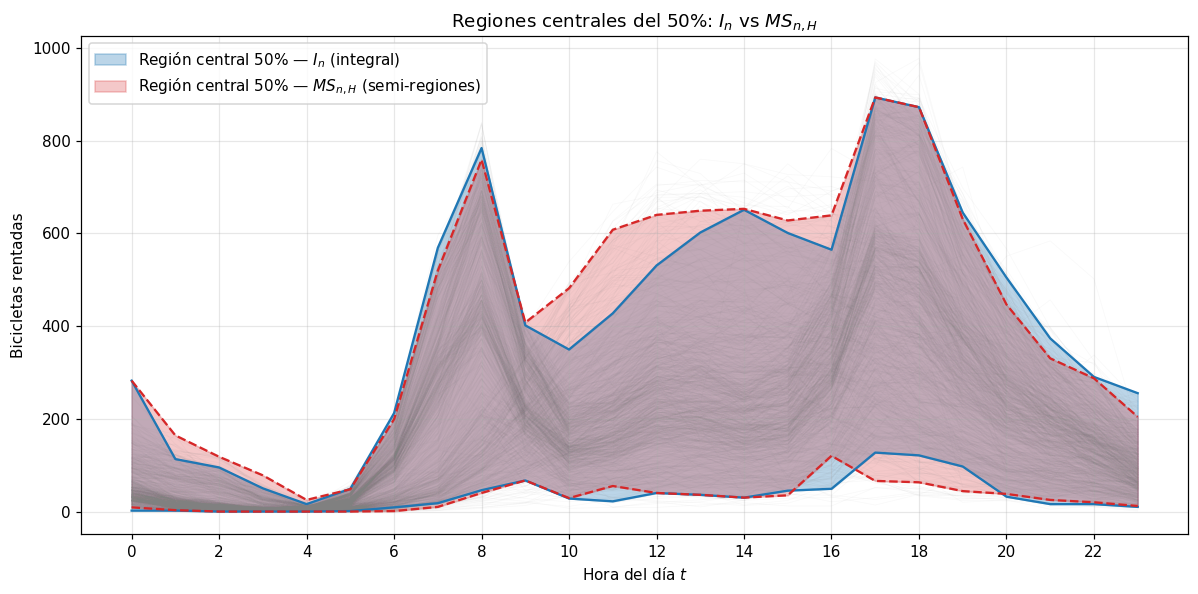

In [ ]:
H = np.arange(24)
fig, ax = plt.subplots(figsize=(11, 5.5))

# Fondo: todas las curvas en gris tenue
for i in range(n_days):
    ax.plot(H, curves[i, :], color='gray', alpha=0.05, linewidth=0.5)

# Regiones centrales
ax.fill_between(H, low_In, up_In, color='C0', alpha=0.30,
                label='Región central 50% — $I_n$ (integral)')
ax.fill_between(H, low_MS, up_MS, color='C3', alpha=0.25,
                label='Región central 50% — $MS_{n,H}$ (semi-regiones)')
ax.plot(H, low_In, 'C0', lw=1.5); ax.plot(H, up_In, 'C0', lw=1.5)
ax.plot(H, low_MS, 'C3', lw=1.5, ls='--'); ax.plot(H, up_MS, 'C3', lw=1.5, ls='--')

ax.set_xlabel("Hora del día $t$")
ax.set_ylabel("Bicicletas rentadas")
ax.set_title("Regiones centrales del 50%: $I_n$ vs $MS_{n,H}$")
ax.set_xticks(range(0, 24, 2))
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

### 4.3 ¿Qué método dio la banda más estrecha?

**Resultado empírico.** La región central del 50% basada en la **profundidad integral $I_n$ es la más estrecha**: su ancho medio es de ~388 bicicletas frente a ~409 de $MS_{n,H}$, y es más angosta en 15 de las 24 horas, sobre todo en los **picos de transporte (17h–18h)**, que es donde más se separan las curvas. La banda de $MS_{n,H}$, en cambio, se ensancha en la meseta del mediodía (10h–16h), como se ve en la gráfica.

**Por qué pasa esto (la teoría detrás).** Las dos profundidades definen "centro" de forma distinta y eso se traduce directamente en el ancho:

- **$I_n$ optimiza centralidad *punto a punto*.** Su 50% más profundo son los días que, hora por hora, se mantienen pegados a la **mediana puntual**. Al pedir cercanía en *cada* instante, la envolvente de esos días queda naturalmente apretada alrededor del cuerpo central → banda angosta.

- **$MS_{n,H}$ optimiza *balance de orden*, no cercanía puntual.** Una curva es profunda si la muestra queda repartida mitad-arriba / mitad-abajo a lo largo del día, **sin importar si cruza a las demás**. Esa es la famosa **tolerancia a cruces**: un día que va alto en la mañana y bajo en la tarde (cruzando al grueso de la muestra) no es penalizado, porque en promedio sigue dejando la muestra balanceada. Como su 50% central **admite ese tipo de curvas oscilantes**, la envolvente resultante es algo **más ancha**.

**En una frase:** $I_n$ premia "estar siempre cerca del medio" (banda estrecha), mientras que $MS_{n,H}$ premia "dejar la muestra balanceada" y tolera cruces (banda más holgada). Las dos son válidas, pero apuntan a cosas distintas: si lo que la empresa quiere es la **franja operativa típica más ajustada** para planear la redistribución, $I_n$ es la indicada; si lo que interesa es un orden de centralidad **robusto a curvas que se cruzan** (días con perfiles raros pero equilibrados), $MS_{n,H}$ es más fiel a la forma. Que ~73% de los días caigan en ambas regiones centrales confirma que las dos coinciden en el grueso; la diferencia de ancho viene de ese ~27% de días oscilantes que solo $MS_{n,H}$ deja entrar.

# Ejercicio 2: Privacidad Diferencial sobre el *Adult / Census Income* (UCI)
## Preparación: librerías y carga de datos



In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)

column_names = ['age','workclass','fnlwgt','education','education-num','marital-status',
                'occupation','relationship','race','sex','capital-gain','capital-loss',
                'hours-per-week','native-country','income']


url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"
df = pd.read_csv(url, names=column_names, skipinitialspace=True)

print("Datos cargados desde:", url)
print("Tamaño total de la base:", df.shape)

Datos cargados desde: https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data
Tamaño total de la base: (32561, 15)


In [ ]:
# Aislamos a los individuos con ingresos > 50K (los 'altos contribuyentes')
df_alto = df[df['income'] == '>50K'][['age', 'education', 'occupation']].copy()
print("Personas con ingresos > 50K:", len(df_alto))
df_alto.head()

Personas con ingresos > 50K: 7841


,age,education,occupation
7,52,HS-grad,Exec-managerial
8,31,Masters,Prof-specialty
9,42,Bachelors,Exec-managerial
10,37,Some-college,Exec-managerial
11,30,Bachelors,Prof-specialty


# 1. Histograma por educación y Mecanismo de Laplace (30%)

Queremos publicar, por nivel educativo, cuántos altos contribuyentes hay. Primero la cuenta exacta (sin
privacidad) y luego la versión protegida con ruido de Laplace para garantizar **$\epsilon$-Privacidad
Diferencial pura** con $\epsilon = 0.5$.

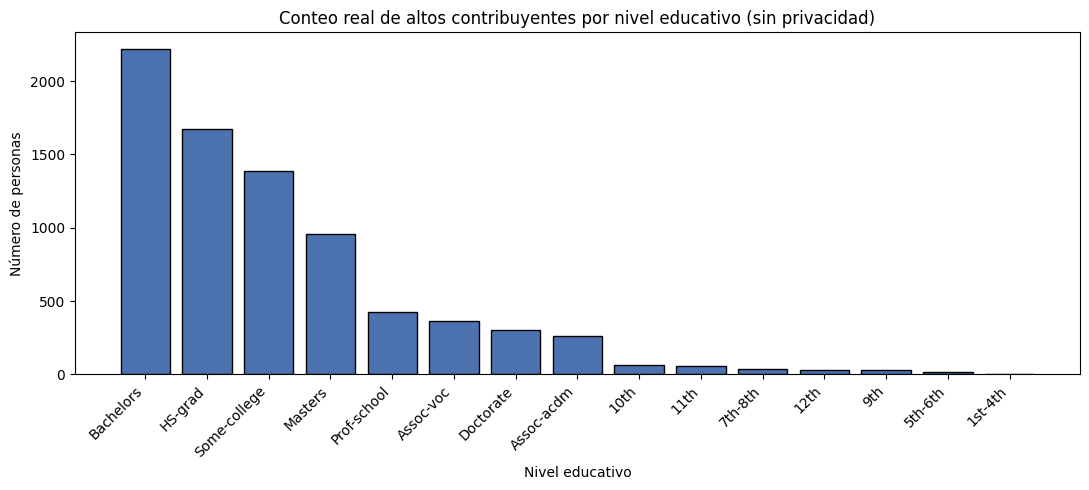

education
Bachelors       2221
HS-grad         1675
Some-college    1387
Masters          959
Prof-school      423
Assoc-voc        361
Doctorate        306
Assoc-acdm       265
10th              62
11th              60
7th-8th           40
12th              33
9th               27
5th-6th           16
1st-4th            6
Name: count, dtype: int64


In [ ]:
# Conteo determinista (exacto) por nivel educativo
education_counts = df_alto['education'].value_counts()

plt.figure(figsize=(11, 5))
plt.bar(education_counts.index, education_counts.values,
        color='#4C72B0', edgecolor='black')
plt.title('Conteo real de altos contribuyentes por nivel educativo (sin privacidad)')
plt.xlabel('Nivel educativo'); plt.ylabel('Número de personas')
plt.xticks(rotation=45, ha='right')
plt.tight_layout(); plt.show()

print(education_counts)

### ¿Cuánto vale la sensibilidad $\Delta_1 f$ de este histograma?

La consulta devuelve un **vector de conteos** (una casilla por nivel educativo). Dos bases son vecinas si
se diferencian en **agregar o quitar una sola persona**.

Aquí cada persona tiene **un único** nivel educativo, así que al agregarla o quitarla solo se mueve **una**
casilla, y se mueve en **1 unidad**. Midiendo ese cambio con la norma $\ell_1$ (suma de los valores
absolutos de las diferencias):

$$\Delta_1 f = \max_{D\sim D'} \lVert f(D)-f(D')\rVert_1 = 1.$$

Es exactamente el caso del histograma epidemiológico visto en clase: para conteos por categorías disjuntas
la sensibilidad $\ell_1$ es siempre **1**. Como Laplace se calibra con la escala $b=\Delta_1 f/\epsilon$,
nos queda $b = 1/0.5 = 2$.

In [ ]:
epsilon = 0.5
delta_f = 1                 # sensibilidad L1 del histograma de conteo
b = delta_f / epsilon       # escala de Laplace = 1 / 0.5 = 2

true_counts = education_counts.values.astype(float)
# Mecanismo de Laplace: a cada casilla le sumamos ruido i.i.d. Laplace(0, b)
ruido = np.random.laplace(loc=0, scale=b, size=len(true_counts))
privados = np.round(true_counts + ruido).astype(int)
privados = np.maximum(privados, 0)   # un conteo no puede ser negativo

tabla = pd.DataFrame({
    'Educacion': education_counts.index,
    'Conteo real': true_counts.astype(int),
    'Ruido Laplace': np.round(ruido, 2),
    'Conteo privado': privados
})
print(f"Escala de Laplace  b = Delta1/epsilon = {delta_f}/{epsilon} = {b}\n")
print(tabla.to_string(index=False))

Escala de Laplace  b = Delta1/epsilon = 1/0.5 = 2.0

   Educacion  Conteo real  Ruido Laplace  Conteo privado
   Bachelors         2221          -0.58            2220
     HS-grad         1675           4.63            1680
Some-college         1387           1.25            1388
     Masters          959           0.44             959
 Prof-school          423          -2.33             421
   Assoc-voc          361          -2.33             359
   Doctorate          306          -4.31             302
  Assoc-acdm          265           2.64             268
        10th           62           0.45              62
        11th           60           1.08              61
     7th-8th           40          -6.38              34
        12th           33           5.62              39
         9th           27           2.19              29
     5th-6th           16          -1.71              14
     1st-4th            6          -2.02               4


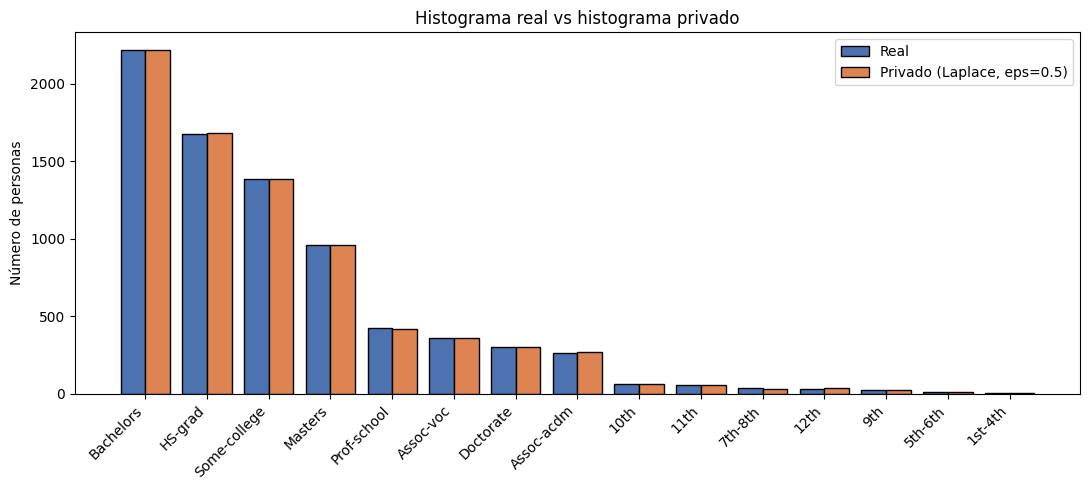

In [ ]:
# Comparación visual: conteo real vs conteo privado
x = np.arange(len(true_counts)); w = 0.4
plt.figure(figsize=(11, 5))
plt.bar(x - w/2, true_counts, w, label='Real', color='#4C72B0', edgecolor='black')
plt.bar(x + w/2, privados,    w, label='Privado (Laplace, eps=0.5)', color='#DD8452', edgecolor='black')
plt.xticks(x, education_counts.index, rotation=45, ha='right')
plt.ylabel('Número de personas'); plt.title('Histograma real vs histograma privado')
plt.legend(); plt.tight_layout(); plt.show()

 El ruido tiene escala 2, así que las casillas se mueven apenas unas pocas
unidades. En las categorías grandes (Bachelors, HS-grad) el cambio es prácticamente invisible y la forma
del histograma se conserva; en las categorías chicas (1st-4th, 5th-6th) ese mismo ruido pesa más en
términos relativos. Esto ilustra una idea central: con $\epsilon$ fijo, el costo de la privacidad es
**absoluto**, no proporcional, y por eso golpea más fuerte a los grupos pequeños.

# 2. Dimensionalidad y sensibilidad geométrica (35%)

Ahora la consulta cambia: queremos publicar la **suma de edades** de los altos contribuyentes, separada por
**ocupación**. Es decir, un vector con una casilla por ocupación, donde cada casilla es la suma de las
edades de las personas de esa ocupación. Por ley la edad se *winsoriza* al intervalo $[17, 90]$ (todo lo
menor a 17 se vuelve 17 y todo lo mayor a 90 se vuelve 90).

*Nota sobre datos:* la ocupación tiene algunos registros `?` (desconocida). Como no es una ocupación real,
la dejamos por fuera para esta parte.

In [ ]:
# Para las partes por ocupacion descartamos la ocupacion desconocida '?'
df_occ = df_alto[df_alto['occupation'] != '?'].copy()

# Winsorizacion de la edad a [17, 90]
df_occ['age_w'] = df_occ['age'].clip(lower=17, upper=90)

# Vector suma de edades por ocupacion
suma_edades = df_occ.groupby('occupation')['age_w'].sum()
ocupaciones = suma_edades.index.tolist()
true_sums = suma_edades.values.astype(float)
d = len(ocupaciones)

print("Numero de ocupaciones (dimension del vector) d =", d, "\n")
print(suma_edades)

Numero de ocupaciones (dimension del vector) d = 14 

occupation
Adm-clerical         21930
Armed-Forces            46
Craft-repair         40609
Exec-managerial      88360
Farming-fishing       5412
Handlers-cleaners     3669
Machine-op-inspct    10597
Other-service         5688
Priv-house-serv         47
Prof-specialty       81196
Protective-serv       8766
Sales                43583
Tech-support         12198
Transport-moving     14239
Name: age_w, dtype: int64


### Sensibilidad $\ell_1$ y $\ell_2$ del vector suma

El enunciado dice que el vecino $D'$ se obtiene **alterando la ocupación *y* la edad de un individuo que ya
estaba** en la base (no agregar ni quitar, sino *cambiar* a alguien). Esto es clave y es donde hay que
tener cuidado:

- Como la persona **cambia de ocupación**, deja de aportar a la casilla de su ocupación vieja (esa suma
  **baja**) y empieza a aportar a la casilla de su ocupación nueva (esa otra suma **sube**). O sea, se
  mueven **dos** casillas, no una.
- La edad está recortada a $[17,90]$, así que el aporte de una persona a su casilla vale a lo sumo **90**.
  En el peor caso, la casilla vieja baja hasta 90 (la persona tenía 90 años) y la casilla nueva sube
  hasta 90.

Con eso, midiendo el cambio en cada norma:

$$\Delta_1 f = \underbrace{90}_{\text{casilla vieja}} + \underbrace{90}_{\text{casilla nueva}} = 180,
\qquad
\Delta_2 f = \sqrt{90^2 + 90^2} = 90\sqrt{2} \approx 127.28.$$

> Cuidado con un error común: si la persona **solo** cambiara de edad pero **no** de ocupación, se movería
> una sola casilla y el cambio máximo sería $90-17=73$. Pero como aquí **también** cambia de ocupación, el
> aporte salta de una casilla a otra y hay que contar **dos** golpes. Por eso la respuesta correcta es
> $\Delta_1=180$ y $\Delta_2=90\sqrt2$, no 73.

Es el mismo esquema de clase: $\ell_1$ suma los golpes por coordenada y $\ell_2$ los combina como catetos
($\Delta_2=\sqrt{\sum c_j^2}$). Calibramos cada mecanismo con la norma que le corresponde: Laplace con
$\Delta_1$ y Gaussiano con $\Delta_2$.

In [ ]:
# Sensibilidades
aporte_max = 90                      # aporte maximo de una persona (edad winsorizada)
delta_l1 = aporte_max + aporte_max               # 180
delta_l2 = np.sqrt(aporte_max**2 + aporte_max**2)
print(f"Sensibilidad L1 (Laplace):  Delta1 = 90 + 90       = {delta_l1}")
print(f"Sensibilidad L2 (Gaussiano): Delta2 = sqrt(90^2+90^2) = {delta_l2:.4f}\n")

# --- Mecanismo de Laplace (usa Delta1)
eps = 0.5
b_lap = delta_l1 / eps               # 180 / 0.5 = 360
ruido_lap = np.random.laplace(0, b_lap, size=d)
priv_lap = true_sums + ruido_lap

# Mecanismo Gaussiano (usa Delta2), (eps, delta)-DP aproximada
delta_priv = 1e-5
z = np.sqrt(2 * np.log(1.25 / delta_priv))
sigma = z * delta_l2 / eps                      # sigma = z * Delta2 / eps
ruido_gauss = np.random.normal(0, sigma, size=d)
priv_gauss = true_sums + ruido_gauss

print(f"Laplace  : escala b = Delta1/eps = {delta_l1}/{eps} = {b_lap}")
print(f"Gaussiano: z = sqrt(2 ln(1.25/{delta_priv})) = {z:.4f}")
print(f"           sigma = z * Delta2 / eps = {sigma:.2f}")

Sensibilidad L1 (Laplace):  Delta1 = 90 + 90       = 180
Sensibilidad L2 (Gaussiano): Delta2 = sqrt(90^2+90^2) = 127.2792

Laplace  : escala b = Delta1/eps = 180/0.5 = 360.0
Gaussiano: z = sqrt(2 ln(1.25/1e-05)) = 4.8448
           sigma = z * Delta2 / eps = 1233.29


In [ ]:
# Error absoluto empirico en cada coordenada = magnitud del ruido inyectado |Y_j|
err_lap = np.abs(ruido_lap)
err_gauss = np.abs(ruido_gauss)

tabla_err = pd.DataFrame({
    'Ocupacion': ocupaciones,
    'Suma real': true_sums.astype(int),
    'Error Laplace |Y|': np.round(err_lap, 1),
    'Error Gauss |Y|': np.round(err_gauss, 1),
})
print(tabla_err.to_string(index=False))
print(f"\nError promedio  Laplace : {err_lap.mean():.1f}")
print(f"Error promedio  Gaussiano: {err_gauss.mean():.1f}")

        Ocupacion  Suma real  Error Laplace |Y|  Error Gauss |Y|
     Adm-clerical      21930              361.0            150.7
     Armed-Forces         46              178.8            635.7
     Craft-repair      40609               18.3            740.3
  Exec-managerial      88360               52.7           1168.5
  Farming-fishing       5412              194.6            358.9
Handlers-cleaners       3669               91.2            783.8
Machine-op-inspct      10597              459.6           1259.9
    Other-service       5688              193.4            199.5
  Priv-house-serv         47              112.0            658.1
   Prof-specialty      81196               33.1              6.8
  Protective-serv       8766              304.1            283.0
            Sales      43583              330.5            480.2
     Tech-support      12198               10.4           1560.3
 Transport-moving      14239               73.6           1346.7

Error promedio  Laplace 

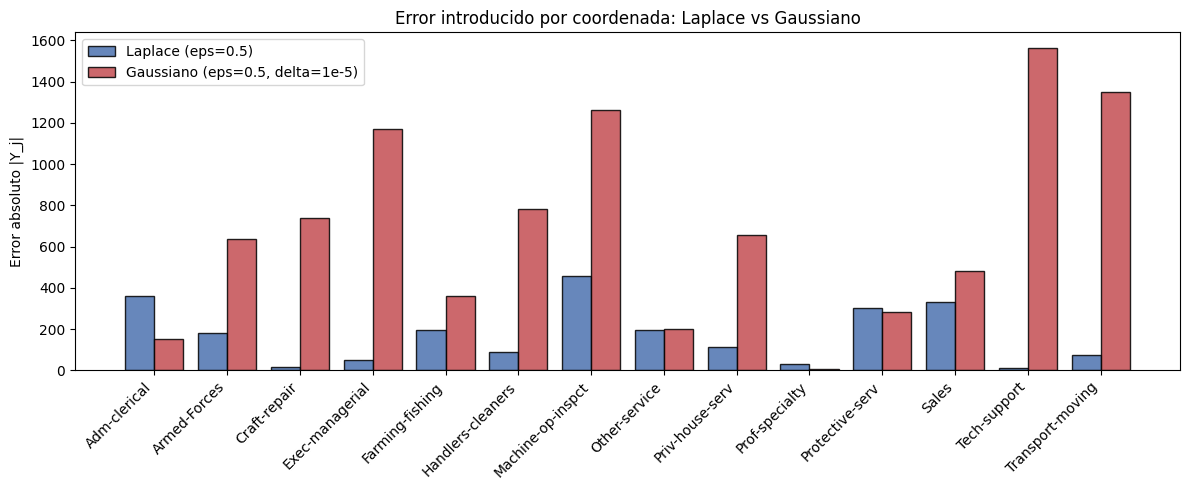

In [ ]:
# Grafico de barras comparativo superpuesto
x = np.arange(d); w = 0.4
plt.figure(figsize=(12, 5))
plt.bar(x - w/2, err_lap,   w, label=f'Laplace (eps={eps})', color='#4C72B0', alpha=0.85, edgecolor='black')
plt.bar(x + w/2, err_gauss, w, label=f'Gaussiano (eps={eps}, delta=1e-5)', color='#C44E52', alpha=0.85, edgecolor='black')
plt.xticks(x, ocupaciones, rotation=45, ha='right')
plt.ylabel('Error absoluto |Y_j|'); plt.title('Error introducido por coordenada: Laplace vs Gaussiano')
plt.legend(); plt.tight_layout(); plt.show()

### Pregunta teórica: ¿por qué Laplace gana aquí?

A simple vista parecería que el Gaussiano debería ganar, porque su sensibilidad es más chica
($\Delta_2 \approx 127$ contra $\Delta_1 = 180$). Pero al ver la gráfica pasa lo contrario: **Laplace mete
mucho menos error**. La razón tiene dos partes:

**1. El Gaussiano paga un “peaje” por el $\delta$.** Para conseguir su versión relajada de privacidad, el
Gaussiano multiplica su ruido por el factor $\sqrt{2\ln(1.25/\delta)}$, que con $\delta=10^{-5}$ vale
$\approx 4.84$. Ese multiplicador es el “Z-score” que controla el riesgo de fuga: pedir un $\delta$ tan
pequeño obliga a inflar bastante la desviación. En números:

- Laplace: error típico $\approx b = 360$.
- Gaussiano: error típico $\approx \sigma\sqrt{2/\pi} \approx 1233 \times 0.8 \approx 984$.

El ahorro geométrico del Gaussiano ($180/127 \approx 1.4$) no alcanza ni de lejos para compensar ese peaje
de $4.84$.

**2. La dimensión es muy baja.** La ventaja real del Gaussiano aparece en **alta dimensión**, porque ahí
$\Delta_2$ crece como $\sqrt{d}$ mientras $\Delta_1$ crece como $d$; cuando $d$ es enorme (miles de
gradientes en *Machine Learning*) ese cociente $\sqrt{d}$ se vuelve gigante y sí compensa el peaje del
$\delta$. Aquí, en cambio, solo se mueven **dos** casillas y el vector tiene apenas $d=14$ ocupaciones, así
que ese efecto $\sqrt{d}$ no existe.

**En resumen:** peaje grande por el $\delta$ + dimensión baja = Laplace gana. En el escenario de ML del
material de clase (miles de dimensiones) la conclusión se invierte y gana el Gaussiano.

# 3. Decisión cualitativa: el Mecanismo Exponencial (35%)

El director pregunta algo que **no es un número** sino una **categoría**: *¿cuál es la ocupación con el
mayor número de altos contribuyentes?* No tiene sentido sumarle ruido a una etiqueta como “Sales”, así que
usamos el **Mecanismo Exponencial**: en vez de perturbar el resultado, perturbamos *la elección*,
dándole más probabilidad a las opciones buenas pero sin entregar siempre la ganadora.

### Espacio de salidas, utilidad y sensibilidad

- **Espacio de salidas $R$:** el conjunto de ocupaciones posibles.
- **Función de utilidad $u(D,r)$:** como la pregunta es por el *mayor número* de contribuyentes, la utilidad
  natural es el **conteo** de altos contribuyentes en la ocupación $r$ (entre más personas, mejor candidata).
- **Sensibilidad $\Delta u$:** al agregar o quitar **una** persona, el conteo de **una** ocupación cambia en
  **1**. Entonces $\Delta u = 1$. Es idéntico al ejemplo de “la enfermedad más frecuente” visto en clase.

> Aquí también hay que tener cuidado: la utilidad es el **conteo de personas**, no la suma de edades. La
> pregunta es por *cuántos*, no por *qué tan viejos*, y por eso $\Delta u = 1$ (no 73 ni 90).

El mecanismo elige cada ocupación con la probabilidad de Gibbs vista en clase:

$$P[\mathcal{A}_E(D)=r] = \frac{\exp\!\big(\tfrac{\epsilon\, u(D,r)}{2\Delta u}\big)}
{\sum_{r'\in R}\exp\!\big(\tfrac{\epsilon\, u(D,r')}{2\Delta u}\big)}.$$

In [ ]:
# Utilidad = numero de altos contribuyentes por ocupacion (un conteo)
utilidad = df_occ['occupation'].value_counts()
R = utilidad.index.tolist()
u = utilidad.values.astype(float)

eps_exp = 1.0
delta_u = 1.0                         # quitar/agregar 1 persona cambia un conteo en 1
escala = eps_exp / (2 * delta_u)

# -Truco Log-Sum-Exp: restamos el maximo antes de exponenciar (evita overflow) --
exponentes = escala * (u - u.max())
log_Z = np.log(np.sum(np.exp(exponentes)))
log_prob = exponentes - log_Z
probabilidades = np.exp(log_prob)

print(f"Espacio R: {len(R)} ocupaciones")
print(f"Sensibilidad Delta_u = {delta_u}")
print(f"Escala del exponente eps/(2 Delta_u) = {escala}\n")

tabla_exp = pd.DataFrame({
    'Ocupacion': R,
    'Utilidad (conteo)': u.astype(int),
    'Probabilidad (%)': np.round(probabilidades * 100, 6)
}).sort_values('Utilidad (conteo)', ascending=False)
print(tabla_exp.to_string(index=False))

Espacio R: 14 ocupaciones
Sensibilidad Delta_u = 1.0
Escala del exponente eps/(2 Delta_u) = 0.5

        Ocupacion  Utilidad (conteo)  Probabilidad (%)
  Exec-managerial               1968             100.0
   Prof-specialty               1859               0.0
            Sales                983               0.0
     Craft-repair                929               0.0
     Adm-clerical                507               0.0
 Transport-moving                320               0.0
     Tech-support                283               0.0
Machine-op-inspct                250               0.0
  Protective-serv                211               0.0
    Other-service                137               0.0
  Farming-fishing                115               0.0
Handlers-cleaners                 86               0.0
     Armed-Forces                  1               0.0
  Priv-house-serv                  1               0.0


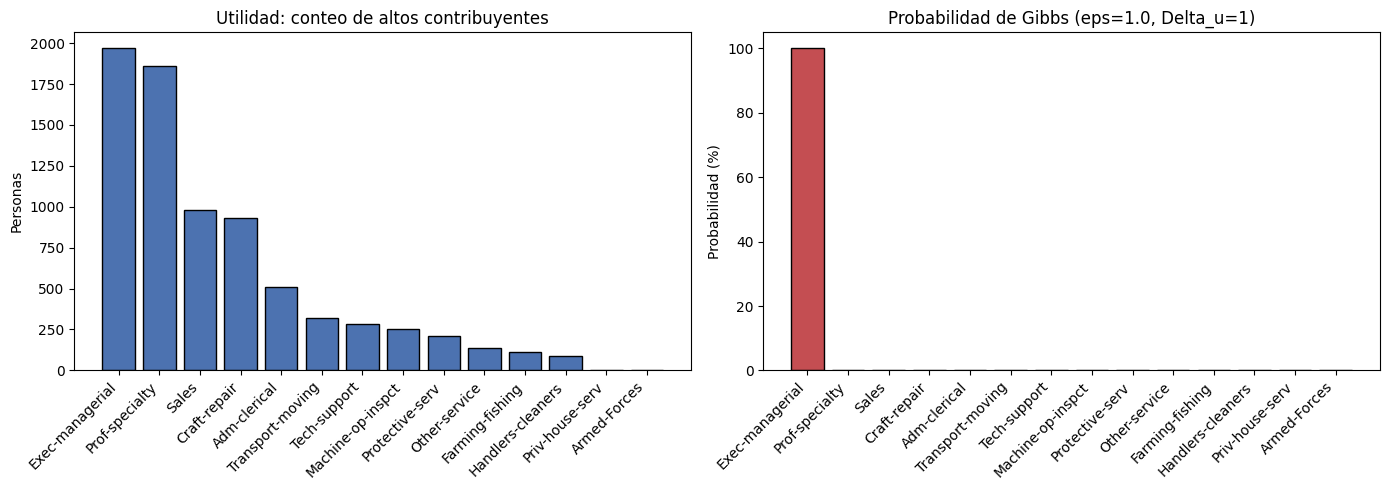

In [ ]:
# Visualizacion: utilidad (conteos) vs probabilidad de Gibbs
orden = np.argsort(u)[::-1]
R_ord = [R[i] for i in orden]; u_ord = u[orden]; p_ord = probabilidades[orden]

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].bar(range(len(R_ord)), u_ord, color='#4C72B0', edgecolor='black')
ax[0].set_title('Utilidad: conteo de altos contribuyentes')
ax[0].set_ylabel('Personas'); ax[0].set_xticks(range(len(R_ord)))
ax[0].set_xticklabels(R_ord, rotation=45, ha='right')

ax[1].bar(range(len(R_ord)), p_ord*100, color='#C44E52', edgecolor='black')
ax[1].set_title(f'Probabilidad de Gibbs (eps={eps_exp}, Delta_u={int(delta_u)})')
ax[1].set_ylabel('Probabilidad (%)'); ax[1].set_xticks(range(len(R_ord)))
ax[1].set_xticklabels(R_ord, rotation=45, ha='right')
plt.tight_layout(); plt.show()

In [ ]:
# Top 3 ocupaciones por utilidad y su probabilidad exacta de seleccion
print("Top 3 ocupaciones con mayor utilidad:\n")
for k in range(3):
    i = orden[k]
    print(f"  {k+1}) {R[i]:<18} conteo = {int(u[i]):>4}   P = {probabilidades[i]*100:.10f} %")

gap = escala * (u[orden[0]] - u[orden[1]])
print(f"\nDiferencia de conteo entre 1ro y 2do: {int(u[orden[0]]-u[orden[1]])}")
print(f"Esa diferencia en el exponente: {gap:.1f}  ->  razon P1/P2 = e^{gap:.1f} ~ {np.exp(gap):.2e}")

Top 3 ocupaciones con mayor utilidad:

  1) Exec-managerial    conteo = 1968   P = 100.0000000000 %
  2) Prof-specialty     conteo = 1859   P = 0.0000000000 %
  3) Sales              conteo =  983   P = 0.0000000000 %

Diferencia de conteo entre 1ro y 2do: 109
Esa diferencia en el exponente: 54.5  ->  razon P1/P2 = e^54.5 ~ 4.67e+23


### Pregunta teórica: ¿por qué la probabilidad colapsa a (casi) 100%?

Mirando la tabla, la ganadora (Exec-managerial) se lleva prácticamente el **100%** y a las demás les queda
una probabilidad casi nula. No es un error de cálculo: es lo que la fórmula tiene que dar con estos datos.

La clave está en el **exponente** $\tfrac{\epsilon\,u(D,r)}{2\Delta u}$. Como $\Delta u = 1$ y $\epsilon=1$,
ese factor vale $0.5$, y los conteos son grandes (cientos o miles). Lo que decide quién gana no es el valor
absoluto sino la **diferencia** entre la primera y la segunda: aquí es $1968-1859=109$. Esa diferencia, en
el exponente, vale $0.5 \times 109 = 54.5$, y al exponenciar:

$$\frac{P(\text{1ra})}{P(\text{2da})} = e^{54.5} \approx 5\times10^{23}.$$

O sea, la ganadora es del orden de $10^{23}$ veces más probable que la segunda. En porcentaje eso es,
para todo efecto práctico, 100% contra 0%.

En el lenguaje termodinámico de la clase, el sistema está a **temperatura baja**
($T=\tfrac{2\Delta u}{\epsilon}=2$): con sensibilidad 1 y $\epsilon$ generoso, el mecanismo se “congela” y
casi siempre devuelve al campeón. Tiene sentido: si una opción gana por un margen tan amplio, el riesgo de
privacidad de revelarla es mínimo (quitar una persona la mueve apenas 1), y por eso el algoritmo puede
darse el lujo de ser casi determinista.